# PD correction performance versus initial RMS and SNR
Sweep initial aberration RMS and initial aberrated z=0, zero-diversity shot-noise SNR, measuring the remaining pupil RMS after **1, 2, and 3 full AO loops**. Each loop acquires a **new** image stack with the accumulated SLM correction applied, jointly fits the current residual and one shared object using **all stacks collected so far**, and applies its negative estimate. Optimization stops using the existing convergence criteria or the configurable iteration cap. An AO loop is not one optimizer step.

This notebook copies the optics, single bead, 17 unknown modes, and joint three-diversity acquisition design from `correction_test`. It uses ordinary illumination, as that notebook does. Exposure is calibrated separately for each RMS/SNR/trial using one **initial aberrated image at z=0 with no diversity and zero SLM correction**. The target is global RMS shot-noise SNR across all pixels in this image. Exposure then stays fixed across all three loops; later SNR can change as correction changes signal. `acquisition_snr` records the expected SNR of each collected stack. Each optimization screens **100 random aberrations plus zero** by loss before running the full exact-Hessian Newton solve from the best candidate. The diversity modes are fixed by AO loop: **loop 1** uses `[-2,2], [0,4], [2,2]`; **loop 2** uses `[-3,3], [0,4], [3,3]`; **loop 3** uses `[-4,4], [0,4], [4,4]`. Each mode has negative, zero, and positive probes at every focus, retaining 72 images per loop. Single-mode bases are normalized with `zernike_RMS`; bias magnitudes specify phase RMS in waves. Diversity amplitudes retain their decay between loops. Every trial and sweep point uses the same mode schedule. Saved basis coefficients, modes by loop, and loop biases reconstruct every applied probe. Ground truth only supplies RMS diagnostics.

The same random wavefront direction is used for a given trial across sweep points, scaled to the requested RMS. Each run has a reproducible, independent noise stream. Increase `NUM_TRIALS` for statistical comparisons; one trial is a quick initial experiment. The full sweep can be expensive.

Results are checkpointed after every completed AO loop to `RESULTS_PATH`. Writes replace the file atomically, so interruption during a write preserves the previous checkpoint. The saved `completed` mask distinguishes finished loops from pending entries (`NaN` residual RMS). Rerunning the sweep starts a new sweep; this saves partial data without automatically resuming it.

This run uses RMS 0.05–0.30 waves and a separate results filename. The old unaberrated-reference sweep remains intact. The saved SNR axis is `target_snr`, and exposure now has shape `(RMS, SNR, trial)`. Higher aberrations can receive longer exposures to meet the same initial SNR; comparisons are at matched initial measurement quality rather than matched exposure.

Historical frames use known phase `diversity + acquisition_SLM - current_SLM`. Fits therefore use 72, 144, and 216 images with the current acquisition settings, while each loop still collects only 72 new images. `REUSE_ACQUISITIONS=False` restores fitting only the latest stack.


In [82]:
from pathlib import Path
import sys
import inspect
import importlib
ROOT = Path.cwd()
while not ((ROOT / "utils").is_dir() and (ROOT / "optimization").is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook inside the repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
EXPERIMENT_DIR = ROOT / "systematic_testing" / "rms_snr_sweep"
FIGURES_DIR = EXPERIMENT_DIR / "figures"
RESULTS_DIR = EXPERIMENT_DIR / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from utils import psf, plotting, zernike
from optimization import reconstruction
from systematic_testing import correction
if "reuse_acquisitions" not in inspect.signature(correction.stack_feedback).parameters:
    importlib.reload(correction)
if "reuse_acquisitions" not in inspect.signature(correction.stack_feedback).parameters:
    raise RuntimeError(f"Update {correction.__file__} to support cumulative acquisition fits.")


In [83]:
plt.style.use("bmh")
plt.rcParams["figure.figsize"] = [548 / 72, 390 / 72]
plt.rcParams["font.size"] = 12
plt.rcParams['text.usetex'] = True
plt.rcParams["figure.dpi"] = 300

In [70]:
N_order = 3                # 3 for 3P, 2 for 2P
lambd = 1.3e-3             # Wavelength [mm]
n = 1.333                  # Refractive index
k = 2*n*np.pi/lambd        # Wavenumber
num_apt = 1.05             # Numerical aperture
f = 7.2                    # Focal length of objective (Olympus) [mm]
grid_size = 128            # BFP resolution
L_bfp = 15.12              # BFP diameter [mm]
mag = 4                    # Magnification rate from input to objective
w_0 = 3.5                  # mm
num_apt = 1.05
L_ffp = 0.0065             # FFP size [mm]
grid_ffp = 32
grid_bfp = 32
microscope = psf.Microscope(N_order = N_order,
                            lambd = lambd,
                            n = n,
                            num_apt = num_apt,
                            f = f,
                            mag = mag,
                            w_0 = w_0,
                            L_bfp = L_bfp,
                            grid_bfp = grid_bfp)

grid = psf.Centered_Square_Grid(L_ffp = L_ffp,
                                grid_ffp = grid_ffp,
                                z_level = 0)

xs, ys = grid.get_xy()


modes = [[-2,2],
         [2,2],
         [-3,3],
         [-1,3],
         [1,3],
         [3,3],
         [-4,4],
         [-2,4],
         [0,4],
         [2,4],
         [4,4],
         [-5,5],
         [-3, 5],
         [-1, 5],
         [1, 5],
         [3, 5],
         [5,5]]

In [84]:
# Sweep axes: pupil RMS in waves and initial aberrated z=0, zero-diversity global shot-noise SNR.
INITIAL_RMS_VALUES = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30])
SNR_VALUES = np.array([5.0, 10.0, 15.0, 20.0, 25.0, 50.0, 100.0])
NUM_TRIALS = 3
ABERRATION_SEED = 0
NOISE_SEED = 1
NUM_AO_LOOPS = 3
BACKEND = "auto"
RHO = 1e46
OPTICAL_MODE = "vector"
REUSE_ACQUISITIONS = True
CORRECTION_GAIN = 1.0
MAX_MODAL_UPDATE = 0.10
NUM_RECONSTRUCTION_PLANES = 21
NUM_STACK_Z_PLANES = 4
STACK_FOCAL_POSITIONS = np.linspace(-0.002, 0.002, NUM_STACK_Z_PLANES)
STACK_DIVERSITY_MODES_BY_LOOP = np.array([
    [[-2, 2], [0, 4], [2, 2]],
    [[-3, 3], [0, 4], [3, 3]],
    [[-4, 4], [0, 4], [4, 4]],
], dtype=int)
NUM_DIVERSITIES = STACK_DIVERSITY_MODES_BY_LOOP.shape[1]
DIVERSITY_MODES = np.array(list(dict.fromkeys(
    tuple(m) for loop_modes in STACK_DIVERSITY_MODES_BY_LOOP for m in loop_modes)))
if not 1 <= NUM_AO_LOOPS <= len(STACK_DIVERSITY_MODES_BY_LOOP):
    raise ValueError("NUM_AO_LOOPS must select between 1 and 3 scheduled loops.")
STACK_DIVERSITY_STRENGTHS = np.array([-0.10, 0.0, 0.10])
STACK_DIVERSITY_DECAY = 1.0
STACK_MIN_DIVERSITY_STRENGTH = 0.02
# Each loop runs a full optimization, with an upper bound on its inner steps.
OPTIMIZER_OPTIONS = dict(method="newton", max_iterations=50, verbose=False,
                         num_random_starts=100, random_start_rms_range=(0.005, 0.50),
                         random_start_seed=0, show_initialization_progress=True)
PRINT_OPTIMIZER_ITERATIONS = False
RESULTS_PATH = ROOT / "systematic_testing" / "rms_snr_sweep" / "results" / "pd_rms_snr_sweep_random100_cumulative_scheduleddiversities_aberrated_z0_snr_rms030.npz"
SNR_CALIBRATION = "initial_aberrated_z0_no_diversity_fixed_exposure"

z_sample_levels = np.linspace(-0.002, 0.002, 41)
z_reconstruction_levels = np.linspace(z_sample_levels[0], z_sample_levels[-1],
                                      NUM_RECONSTRUCTION_PLANES)
mask_3D = psf.bead_img_3D(grid, z_sample_levels, [0], [0], [0], [0.001])
backend = reconstruction.get_backend(BACKEND)
for name, values in [("INITIAL_RMS_VALUES", INITIAL_RMS_VALUES),
                     ("SNR_VALUES", SNR_VALUES)]:
    if np.ndim(values) != 1 or len(values) == 0 or not np.all(np.isfinite(values)) or np.any(values <= 0):
        raise ValueError(f"{name} must contain positive finite values.")
if len(np.unique(INITIAL_RMS_VALUES)) != len(INITIAL_RMS_VALUES):
    raise ValueError("INITIAL_RMS_VALUES must not contain duplicate values.")
if not isinstance(NUM_TRIALS, (int, np.integer)) or NUM_TRIALS < 1:
    raise ValueError("NUM_TRIALS must be a positive integer.")
frames_per_loop = (len(STACK_FOCAL_POSITIONS)*NUM_DIVERSITIES
                   *len(STACK_DIVERSITY_STRENGTHS))
image_budget = NUM_AO_LOOPS*frames_per_loop
print(f"Backend: {backend}; {frames_per_loop} fresh images per AO loop, "
      f"{image_budget} images per run")
print(f"Sweep: {len(INITIAL_RMS_VALUES)*len(SNR_VALUES)*NUM_TRIALS} runs; "
      f"up to {OPTIMIZER_OPTIONS['max_iterations']} Newton steps per loop")

Backend: cpu; 36 fresh images per AO loop, 108 images per run
Sweep: 126 runs; up to 50 Newton steps per loop


In [85]:
# Calibrate from the initial aberrated z=0 image with no diversity; then fix exposure.
# Global shot-noise SNR = sqrt(sum((exposure*I)**2) / sum(exposure*I)).
# I is the single z=0, zero-diversity image, before any SLM correction.
wavefront_directions = np.array([
    np.random.default_rng(np.random.SeedSequence([ABERRATION_SEED, trial])).normal(size=len(modes))
    for trial in range(NUM_TRIALS)])
# Fixed single-mode bases; normalize their pupil RMS as in the previous probe design.
diversity_basis_strengths = np.zeros((NUM_TRIALS, NUM_AO_LOOPS,
                                      NUM_DIVERSITIES, len(DIVERSITY_MODES)))
for loop in range(NUM_AO_LOOPS):
    for probe, probe_mode in enumerate(STACK_DIVERSITY_MODES_BY_LOOP[loop]):
        unit_aberration = zernike.RMSAberration(
            modes=[probe_mode], raw_strengths=[1.0],
            RMS_desired=1.0, alpha=microscope.alpha)
        mode_index = np.flatnonzero(np.all(DIVERSITY_MODES == probe_mode, axis=1))[0]
        diversity_basis_strengths[:, loop, probe, mode_index] = unit_aberration.strengths[0]
loop_diversity_strengths = np.array([
    np.sign(STACK_DIVERSITY_STRENGTHS)*np.maximum(
        np.abs(STACK_DIVERSITY_STRENGTHS)*STACK_DIVERSITY_DECAY**loop,
        np.minimum(np.abs(STACK_DIVERSITY_STRENGTHS), STACK_MIN_DIVERSITY_STRENGTH))
    for loop in range(NUM_AO_LOOPS)])
diversity_schedules = [
    [[zernike.Aberration(DIVERSITY_MODES, basis*float(bias))
      for basis in diversity_basis_strengths[trial, loop]
      for bias in loop_diversity_strengths[loop]]
     for loop in range(NUM_AO_LOOPS)] for trial in range(NUM_TRIALS)]
initial_focal_z = np.repeat(STACK_FOCAL_POSITIONS,
                            NUM_DIVERSITIES*len(STACK_DIVERSITY_STRENGTHS))
exposures = np.full((len(INITIAL_RMS_VALUES), len(SNR_VALUES), NUM_TRIALS), np.nan)
initial_clean_stacks = {}
calibration_clean_images = {}
with tqdm(total=len(INITIAL_RMS_VALUES)*NUM_TRIALS,
          desc="Calibrating aberrated z=0 images", unit="case") as calibration_progress:
    for ri, rms in enumerate(INITIAL_RMS_VALUES):
        for trial in range(NUM_TRIALS):
            truth = zernike.RMSAberration(
                modes=modes, raw_strengths=wavefront_directions[trial],
                RMS_desired=float(rms), alpha=microscope.alpha)
            calibration_image = microscope.compute_image_3D(
                mask_3D, truth, [0.0], mode=OPTICAL_MODE, diversities=None)[3]
            calibration_clean_images[(ri, trial)] = calibration_image
            exposures[ri, :, trial] = [correction.exposure_for_snr(calibration_image, float(snr))
                                       for snr in SNR_VALUES]
            # Cache the separate, diverse PD stack for previews and the first acquisition.
            clean = microscope.compute_image_3D(
                mask_3D, truth, initial_focal_z, mode=OPTICAL_MODE,
                diversities=[probe for _ in STACK_FOCAL_POSITIONS
                             for probe in diversity_schedules[trial][0]])[3]
            initial_clean_stacks[(ri, trial)] = clean
            calibration_progress.update(1)
print("Aberrated z=0, zero-diversity calibration complete; first-loop clean images cached for reuse.")


def expected_stack_snr(clean_images, exposure):
    """Expected global RMS shot-noise SNR, not a noisy realization's estimate."""
    clean = np.maximum(np.asarray(clean_images, dtype=float), 0)
    peak = float(clean.max())
    if peak == 0:
        return 0.0
    unit = clean/peak
    return float(np.sqrt(exposure*peak*np.sum(unit**2)/unit.sum()))


class SweepSLM(correction.SimulatedSLM):
    """Reuse cached PD images for loop 1 and record actual stack SNR each loop."""
    def __init__(self, *args, initial_clean, **kwargs):
        super().__init__(*args, **kwargs)
        self.initial_clean = initial_clean
        self.acquisition_snrs = []

    def acquire(self, focal_z_levels, diversities=None):
        if self.images_taken == 0:
            clean = self.initial_clean
        else:
            clean = self.microscope.compute_image_3D(
                self.sample, self._residual(), focal_z_levels,
                diversities=diversities, mode=self.optical_mode)[3]
        if (not np.all(np.isfinite(clean)) or
                clean.min() < -1e-12*max(float(clean.max()), 0)):
            raise ValueError("Simulated images must be finite and nonnegative.")
        counts = self.rng.poisson(self.exposure*np.maximum(clean, 0))
        self.images_taken += len(counts)
        self.photons_detected += int(counts.sum())
        self.acquisition_snrs.append(expected_stack_snr(clean, self.exposure))
        return counts/self.exposure


Calibrating aberrated z=0 images:   0%|          | 0/18 [00:00<?, ?case/s]

Calibrating aberrated z=0 images: 100%|██████████| 18/18 [00:07<00:00,  2.45case/s]

Aberrated z=0, zero-diversity calibration complete; first-loop clean images cached for reuse.


## Preview before running the sweep
These cells show the single bead, the trial's true aberration at each RMS, and noisy PD observations across the RMS–SNR grid. SNR labels give the prescribed **initial aberrated z=0, zero-diversity image** SNR. Individual frames can have different SNR, and each noise realization fluctuates.

Previews use the same wavefront direction and exposure factors as the sweep, with a separate noise stream. They do not change sweep RNGs or spend the sweep's image budget. One acquisition focus is selected below for a compact view; the full sweep still acquires every configured focal plane.

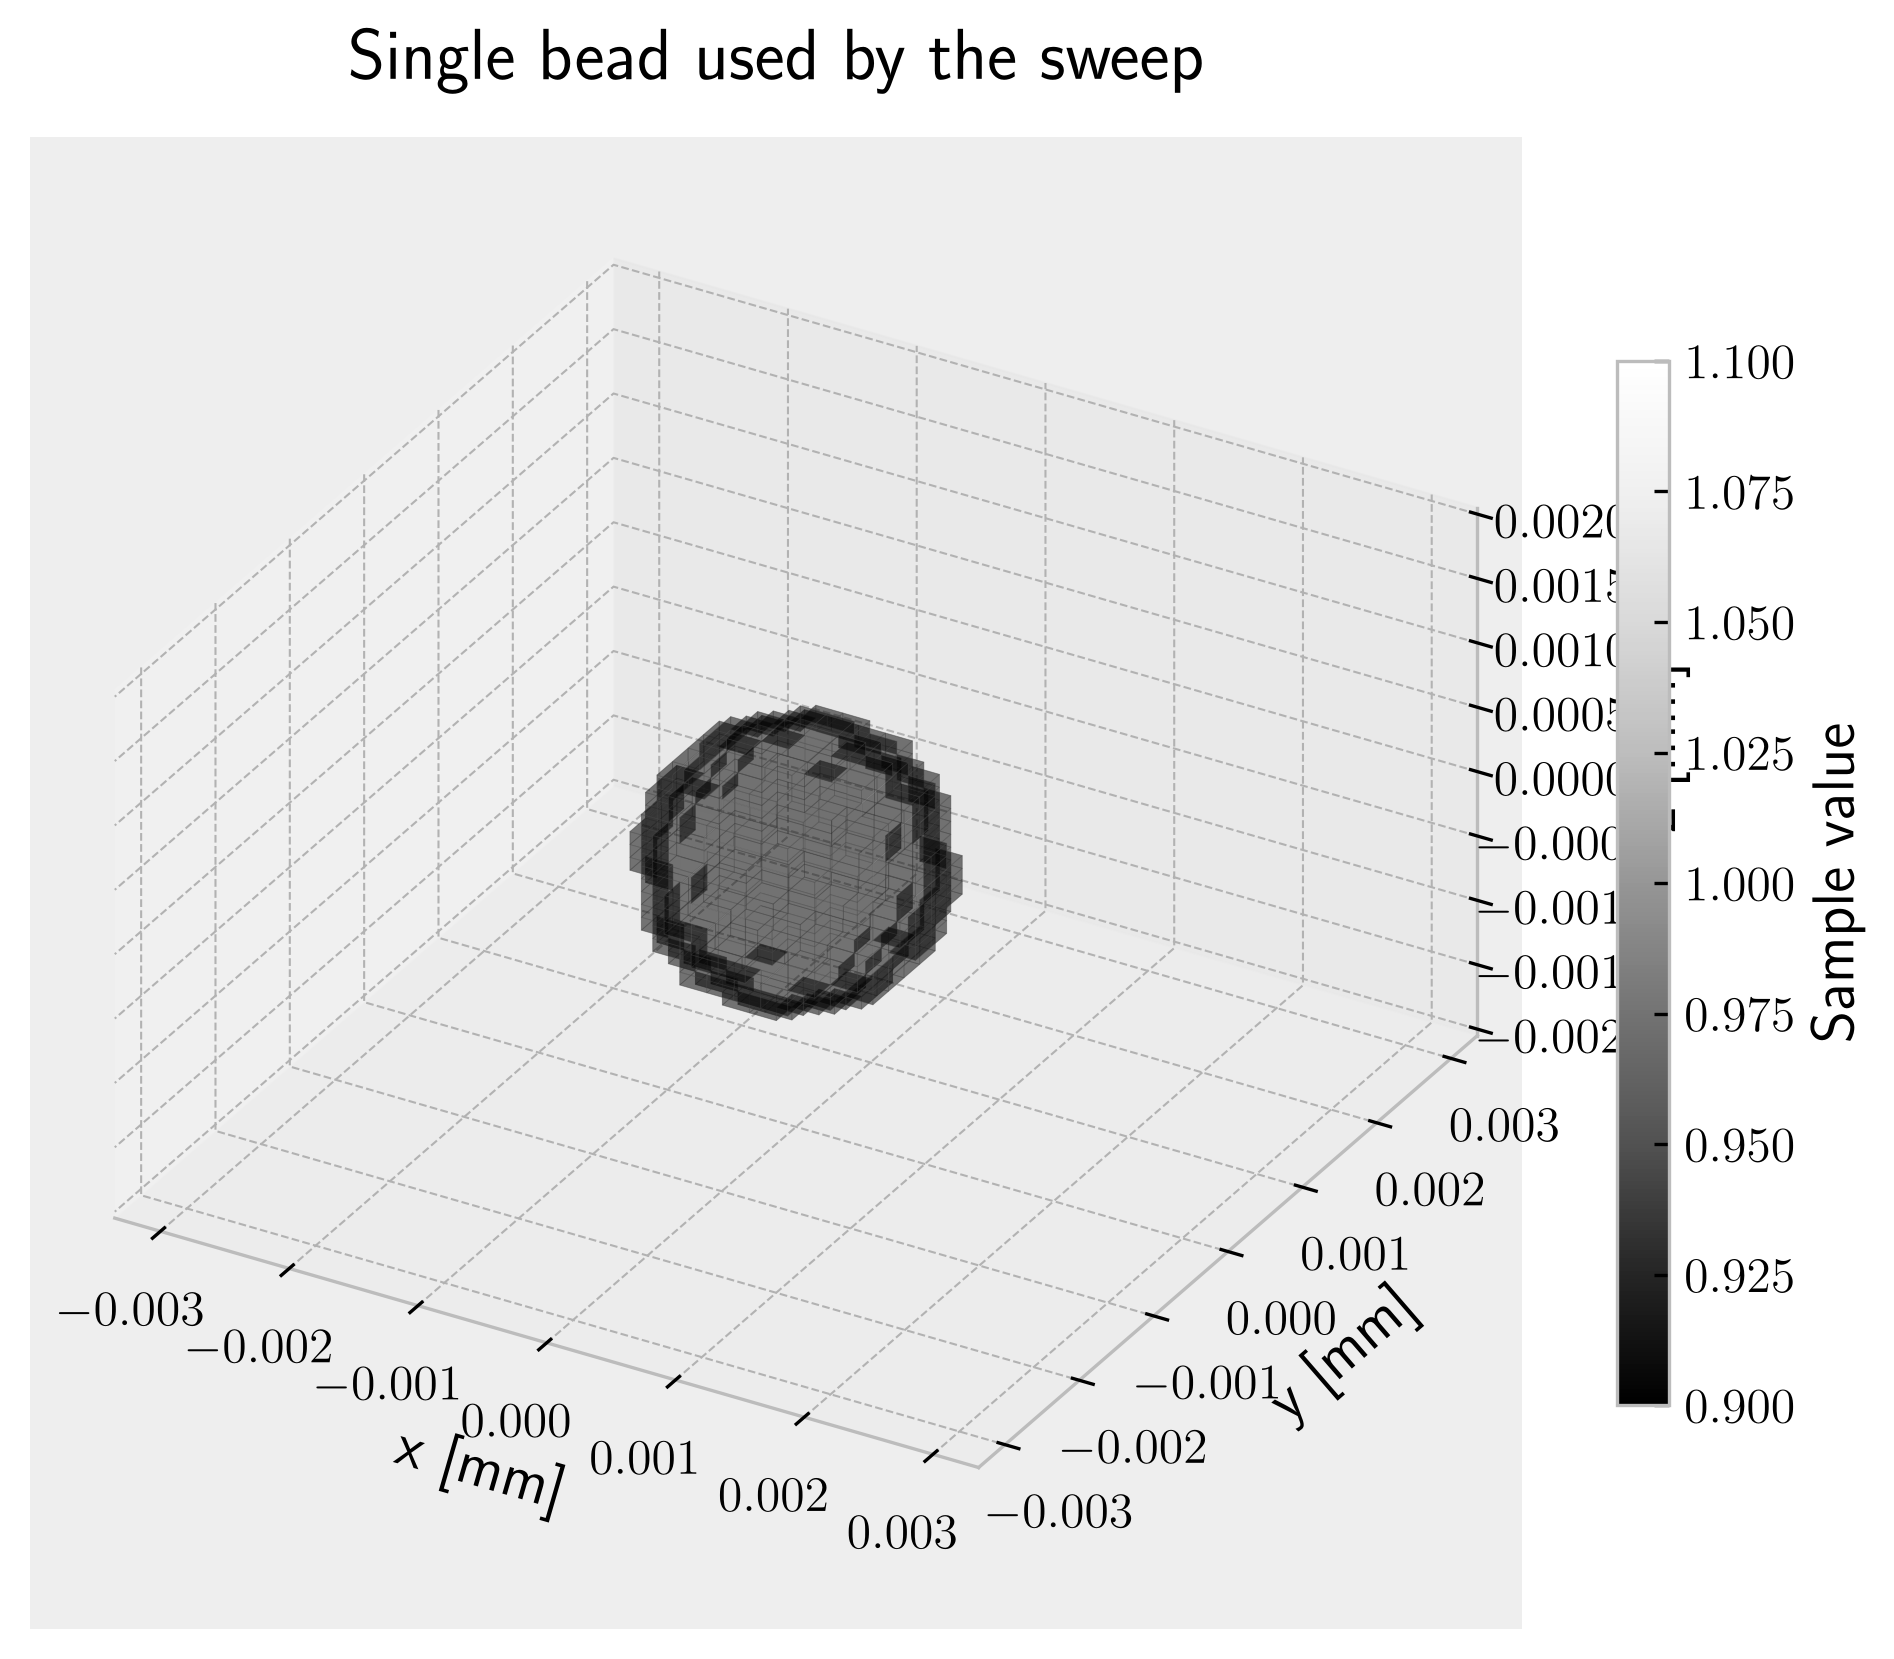

In [86]:
PREVIEW_TRIAL = 0  # Zero-based trial index.
PREVIEW_FOCUS_INDEX = int(np.argmin(np.abs(STACK_FOCAL_POSITIONS)))
PREVIEW_RMS_INDEX = len(INITIAL_RMS_VALUES)//2
PREVIEW_SNR_INDEX = len(SNR_VALUES)//2
if not 0 <= PREVIEW_TRIAL < NUM_TRIALS:
    raise ValueError("PREVIEW_TRIAL must select a configured trial.")
preview_focus = float(STACK_FOCAL_POSITIONS[PREVIEW_FOCUS_INDEX])
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, layout="constrained")
plotting.plot_sample_3D(mask_3D, ax=ax, show=False)
ax.set_title("Single bead used by the sweep", pad=14)
plt.show()

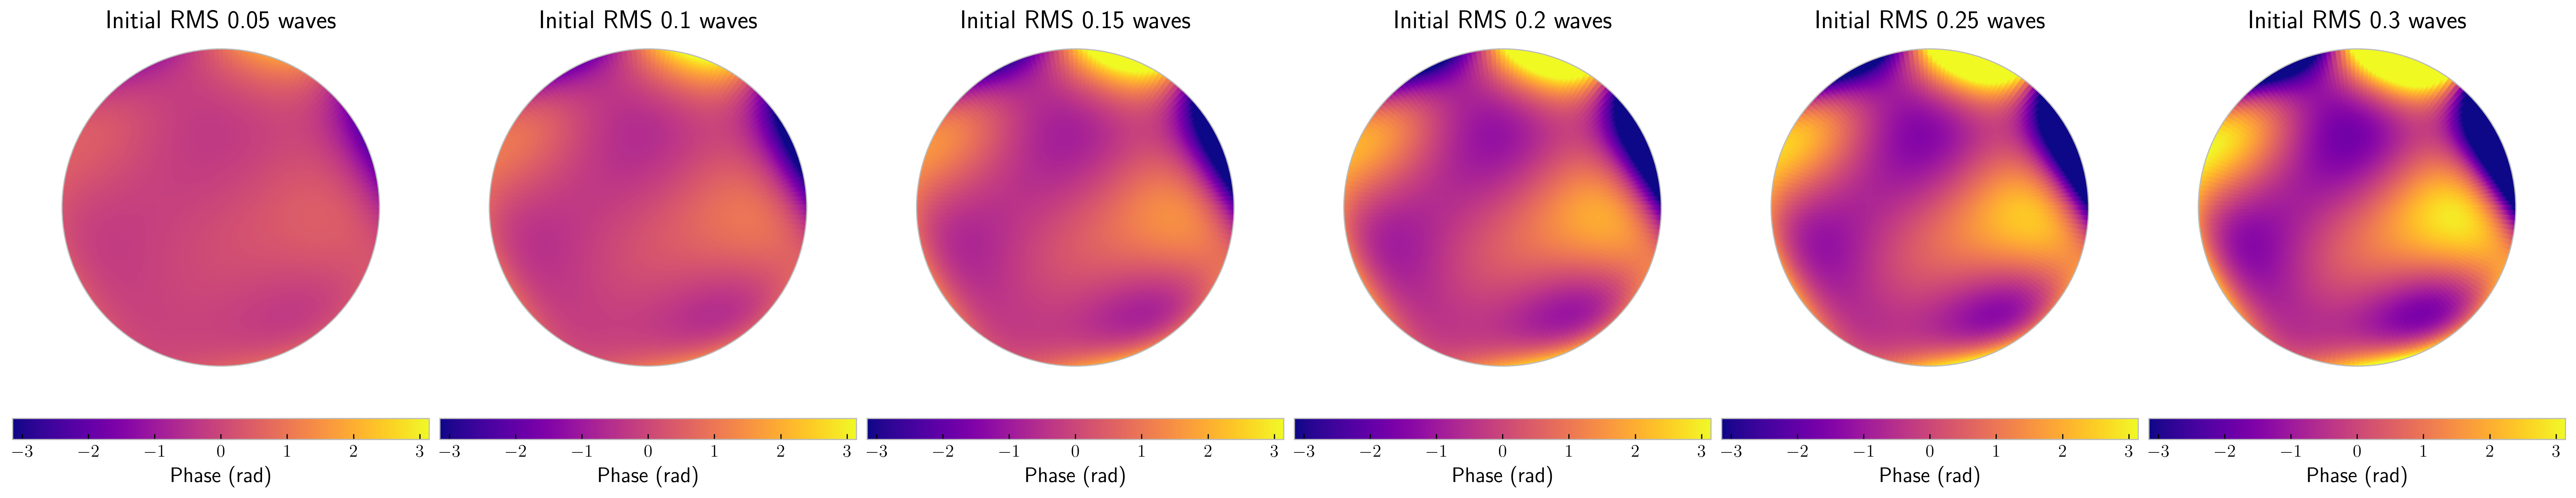

In [90]:
PREVIEW_TRIAL = 2
# Same arbitrary modal mixture at each prescribed RMS, as in the main sweep.
preview_truths = [zernike.RMSAberration(
    modes=modes, raw_strengths=wavefront_directions[PREVIEW_TRIAL],
    RMS_desired=float(rms), alpha=microscope.alpha) for rms in INITIAL_RMS_VALUES]
phase_rho, phase_phi = np.meshgrid(np.linspace(0, 1, 101),
                                 np.linspace(0, 2*np.pi, 101), indexing="ij")
phase_theta = np.arcsin(phase_rho*np.sin(microscope.alpha))
preview_phase_limit = max(np.pi, max(float(np.max(np.abs(
    a.construct_map(microscope.alpha)(phase_theta, phase_phi)))) for a in preview_truths))
fig = plt.figure(figsize=(4*len(preview_truths), 4.8), layout="constrained")
phase_layout = fig.add_gridspec(2, len(preview_truths), height_ratios=[1, .07])
for i, aberration in enumerate(preview_truths):
    ax = fig.add_subplot(phase_layout[0, i], projection="polar")
    plotting.zernike_plot(aberration.construct_map(microscope.alpha), microscope.alpha,
                         res=201, ax=ax, show=False, colorbar=True)
    ax.set_title(f"Initial RMS {INITIAL_RMS_VALUES[i]:g} waves", pad=14)

plt.show()

In [91]:
# All three first-loop diversity modes at one configured focus; re-use clean simulations across SNRs.
preview_diversities = diversity_schedules[PREVIEW_TRIAL][0]
preview_focal_z = np.full(len(preview_diversities), preview_focus)
preview_images = {}
preview_frames_per_focus = len(preview_diversities)
preview_frame_slice = slice(PREVIEW_FOCUS_INDEX*preview_frames_per_focus,
                            (PREVIEW_FOCUS_INDEX+1)*preview_frames_per_focus)
preview_x, preview_y = grid.get_xy()
for ri, aberration in enumerate(preview_truths):
    clean = initial_clean_stacks[(ri, PREVIEW_TRIAL)][preview_frame_slice]
    for si in range(len(SNR_VALUES)):
        exposure = float(exposures[ri, si, PREVIEW_TRIAL])
        preview_rng = np.random.default_rng(np.random.SeedSequence(
            [NOISE_SEED, ri, si, PREVIEW_TRIAL, 9901]))
        preview_images[(ri, si)] = preview_rng.poisson(
            exposure*np.maximum(clean, 0))/exposure
print(f"Preview images ready at focus {preview_focus*1000:+.3f} um.")

# Existing plotting helper, with dedicated colorbar space and compact shared labels.
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
def plot_preview_grid(image_rows, row_labels, column_labels, title):
    image_rows = np.asarray(image_rows)
    nr, nc = image_rows.shape[:2]
    fig = plt.figure(figsize=(3*nc+.8, 2.8*nr+.8), layout="constrained")
    layout = fig.add_gridspec(nr, nc+1, width_ratios=[1]*nc+[.06])
    axes = np.array([[fig.add_subplot(layout[r, c]) for c in range(nc)] for r in range(nr)])
    plotting.plot_many_intensity(axes, preview_x, preview_y,
                                image_rows.reshape(-1, len(preview_x), len(preview_y)),
                                normalize=False)
    for r in range(nr):
        for c in range(nc):
            ax = axes[r, c]
            ax.tick_params(axis="both", labelrotation=0, labelbottom=r == nr-1, labelleft=c == 0)
            ax.xaxis.set_major_locator(MaxNLocator(3))
            ax.yaxis.set_major_locator(MaxNLocator(3))
            ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
            ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
            ax.set_title(column_labels[c] if r == 0 else "", pad=10)
            ax.set_xlabel("x [mm]" if r == nr-1 else "")
            ax.set_ylabel(row_labels[r]+"\ny [mm]" if c == 0 else "")
    fig.suptitle(title, fontsize=12)
    fig.colorbar(axes[0, 0].images[0], cax=fig.add_subplot(layout[:, -1]),
                 label="Measured intensity (shared raw scale)")
    plt.show()
    return fig, axes

Preview images ready at focus +0.667 um.


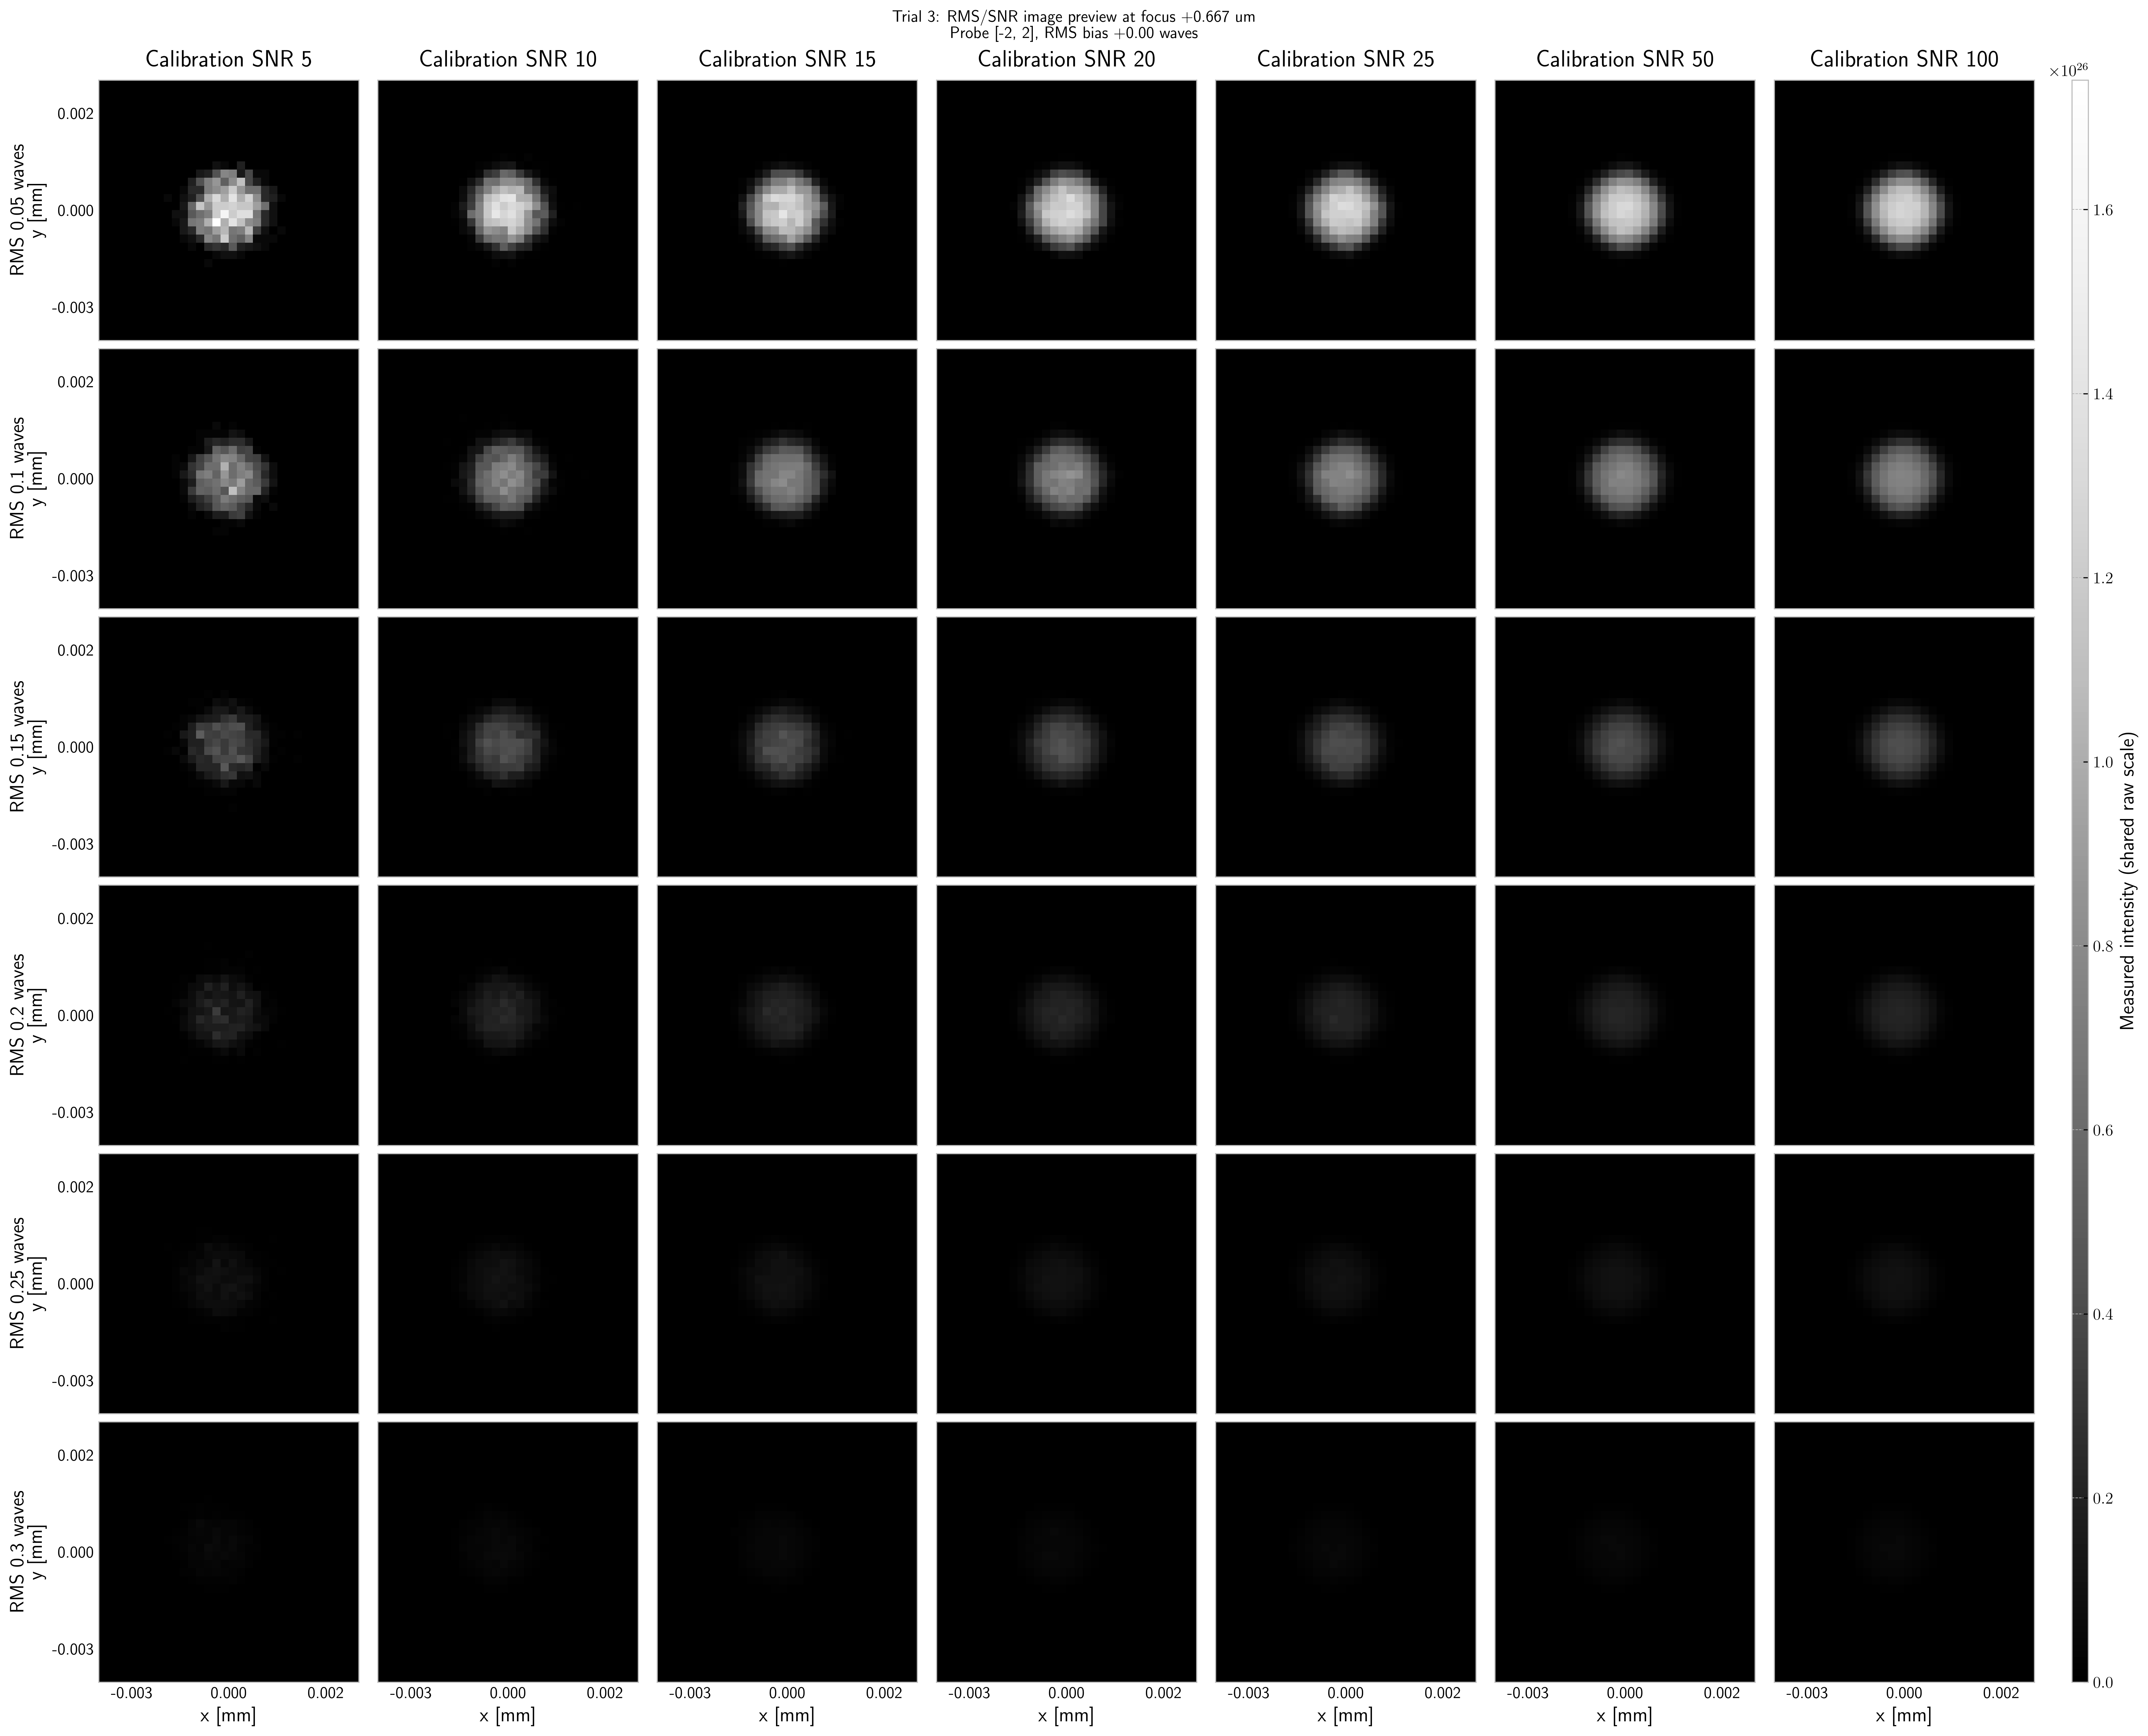

(<Figure size 6540x5280 with 43 Axes>,
 array([[<Axes: title={'center': 'Calibration SNR 5'}, ylabel='RMS 0.05 waves\ny [mm]'>,
         <Axes: title={'center': 'Calibration SNR 10'}>,
         <Axes: title={'center': 'Calibration SNR 15'}>,
         <Axes: title={'center': 'Calibration SNR 20'}>,
         <Axes: title={'center': 'Calibration SNR 25'}>,
         <Axes: title={'center': 'Calibration SNR 50'}>,
         <Axes: title={'center': 'Calibration SNR 100'}>],
        [<Axes: ylabel='RMS 0.1 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='RMS 0.15 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='RMS 0.2 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='RMS 0.25 waves\ny [mm]'>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: xlabel='x [mm]', ylabel='RMS 0.3 w

In [92]:
# Show the same probe for every RMS/SNR combination.
preview_bias_index = int(np.argmin(np.abs(STACK_DIVERSITY_STRENGTHS)))
preview_overview = np.array([[preview_images[(ri, si)][preview_bias_index]
                             for si in range(len(SNR_VALUES))]
                            for ri in range(len(INITIAL_RMS_VALUES))])
plot_preview_grid(
    preview_overview, [f"RMS {r:g} waves" for r in INITIAL_RMS_VALUES],
    [f"Calibration SNR {s:g}" for s in SNR_VALUES],
    f"Trial {PREVIEW_TRIAL+1}: RMS/SNR image preview at focus {preview_focus*1000:+.3f} um\n"
    f"Probe {STACK_DIVERSITY_MODES_BY_LOOP[0, 0].tolist()}, RMS bias {STACK_DIVERSITY_STRENGTHS[preview_bias_index]:+.2f} waves")

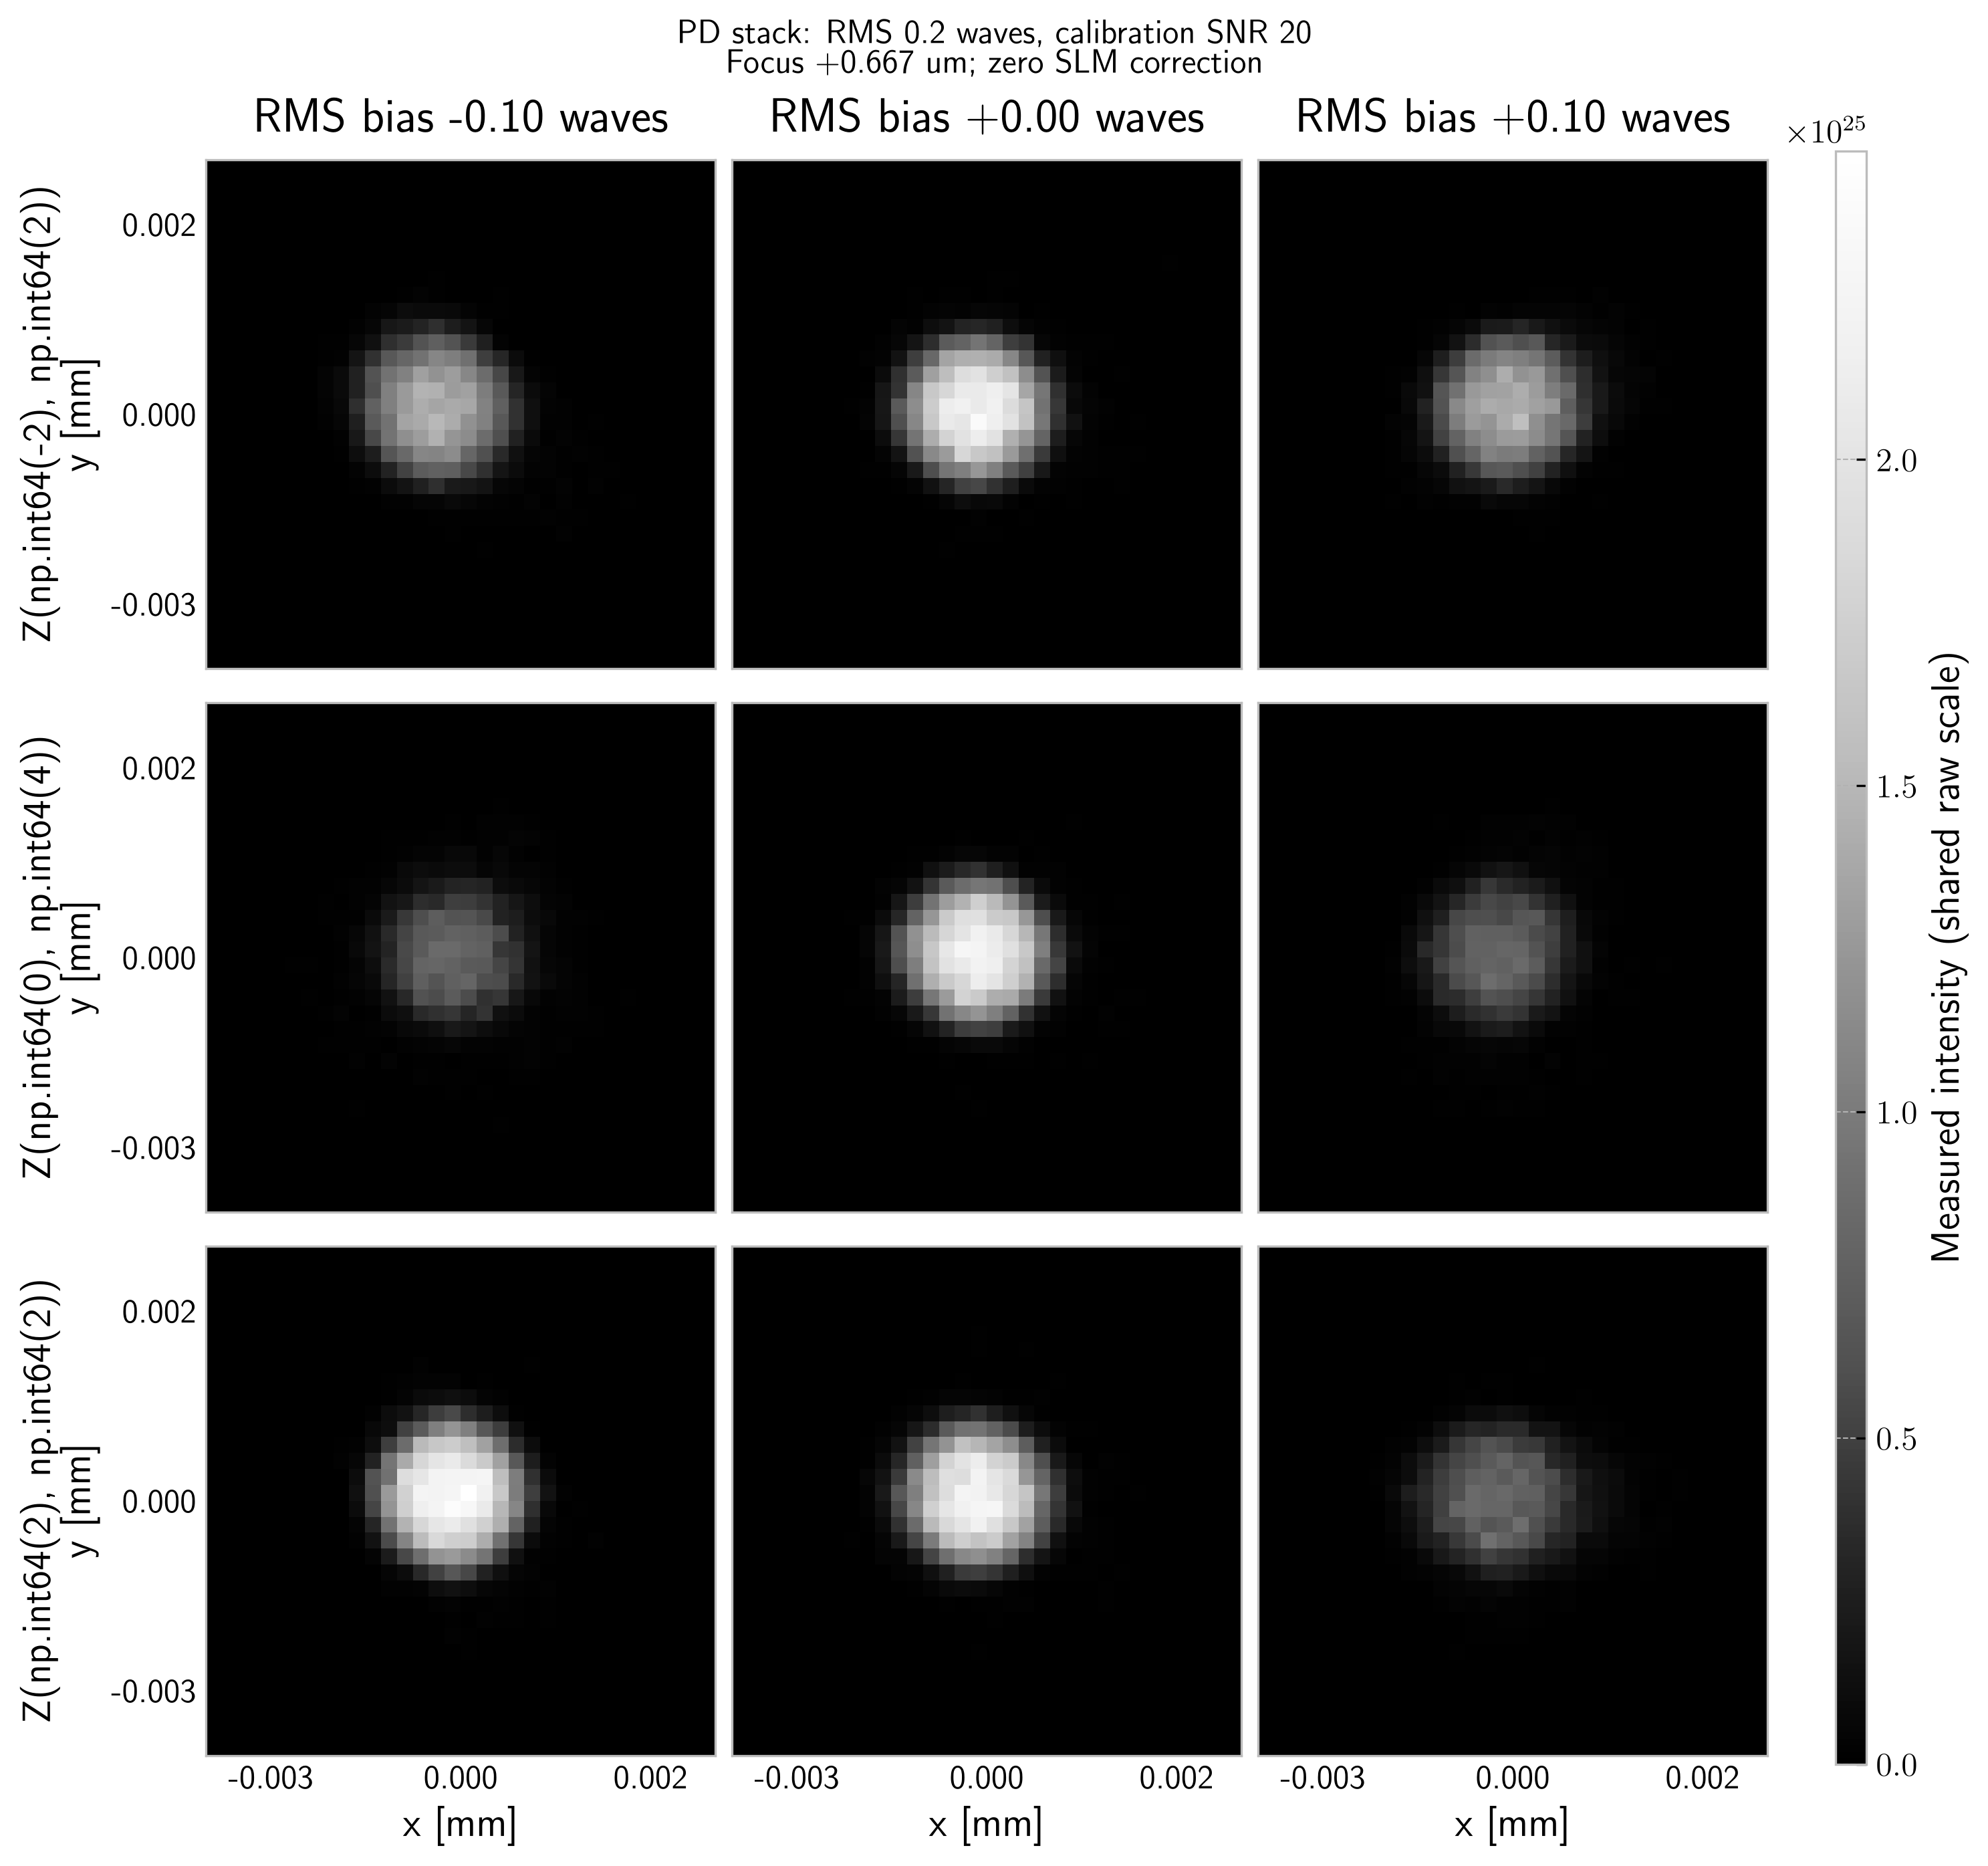

(<Figure size 2940x2760 with 10 Axes>,
 array([[<Axes: title={'center': 'RMS bias -0.10 waves'}, ylabel='Z(np.int64(-2), np.int64(2))\ny [mm]'>,
         <Axes: title={'center': 'RMS bias +0.00 waves'}>,
         <Axes: title={'center': 'RMS bias +0.10 waves'}>],
        [<Axes: ylabel='Z(np.int64(0), np.int64(4))\ny [mm]'>, <Axes: >,
         <Axes: >],
        [<Axes: xlabel='x [mm]', ylabel='Z(np.int64(2), np.int64(2))\ny [mm]'>,
         <Axes: xlabel='x [mm]'>, <Axes: xlabel='x [mm]'>]], dtype=object))

In [93]:
# Inspect every diversity image for one chosen RMS/SNR pair.
preview_selected = preview_images[(PREVIEW_RMS_INDEX, PREVIEW_SNR_INDEX)].reshape(
    NUM_DIVERSITIES, len(STACK_DIVERSITY_STRENGTHS), len(preview_x), len(preview_y))
plot_preview_grid(
    preview_selected,
    [f"Z{tuple(m)}" for m in STACK_DIVERSITY_MODES_BY_LOOP[0]],
    [f"RMS bias {b:+.2f} waves" for b in STACK_DIVERSITY_STRENGTHS],
    f"PD stack: RMS {INITIAL_RMS_VALUES[PREVIEW_RMS_INDEX]:g} waves, "
    f"calibration SNR {SNR_VALUES[PREVIEW_SNR_INDEX]:g}\n"
    f"Focus {preview_focus*1000:+.3f} um; zero SLM correction")

In [94]:
# Save after each completed AO loop. Atomic replacement preserves the last good file.
import os
import tempfile

def save_sweep_checkpoint():
    destination = RESULTS_PATH.resolve()
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(mode="wb", dir=destination.parent,
                                         prefix=destination.name+".", suffix=".tmp",
                                         delete=False) as stream:
            temporary = Path(stream.name)
            np.savez_compressed(
                stream, initial_rms=INITIAL_RMS_VALUES, target_snr=SNR_VALUES,
                snr_calibration=SNR_CALIBRATION, calibration_z=0.0,
                calibration_diversity_strength=0.0, acquisition_snr=acquisition_snr,
                ao_loops=np.arange(1, NUM_AO_LOOPS+1), residual_rms=residual_rms,
                completed=np.isfinite(residual_rms),
                optimizer_loss=optimizer_loss, optimizer_steps=optimizer_steps,
                optimizer_success=optimizer_success, images_taken=images_taken,
                fit_image_count=fit_image_count, reuse_acquisitions=REUSE_ACQUISITIONS,
                slm_strengths=slm_strengths, truth_strengths=truth_strengths, modes=np.asarray(modes),
                exposures=exposures, wavefront_directions=wavefront_directions,
                rho=RHO, correction_gain=CORRECTION_GAIN, max_modal_update=MAX_MODAL_UPDATE,
                focal_positions=STACK_FOCAL_POSITIONS, diversity_modes=DIVERSITY_MODES,
                diversity_modes_by_loop=STACK_DIVERSITY_MODES_BY_LOOP[:NUM_AO_LOOPS],
                num_diversities=NUM_DIVERSITIES,
                diversity_basis_strengths=diversity_basis_strengths,
                loop_diversity_strengths=loop_diversity_strengths,
                diversity_strengths=STACK_DIVERSITY_STRENGTHS, diversity_decay=STACK_DIVERSITY_DECAY,
                min_diversity_strength=STACK_MIN_DIVERSITY_STRENGTH,
                sample_z=z_sample_levels, reconstruction_z=z_reconstruction_levels,
                aberration_seed=ABERRATION_SEED, noise_seed=NOISE_SEED,
                max_optimizer_iterations=OPTIMIZER_OPTIONS['max_iterations'], backend=backend,
                num_random_starts=OPTIMIZER_OPTIONS['num_random_starts'],
                random_start_rms_range=OPTIMIZER_OPTIONS['random_start_rms_range'],
                random_start_seed=OPTIMIZER_OPTIONS['random_start_seed'])
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temporary, destination)
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)

# Reload partial results with np.load(RESULTS_PATH, allow_pickle=False).
# 'completed' identifies saved loops; unfinished residuals remain NaN.


In [96]:
# This starts a fresh sweep; choose a new RESULTS_PATH if you already ran it.
if RESULTS_PATH.exists():
    raise FileExistsError(f"Results already exist: {RESULTS_PATH}. Choose a new RESULTS_PATH to keep them.")
shape = (len(INITIAL_RMS_VALUES), len(SNR_VALUES), NUM_TRIALS, NUM_AO_LOOPS)
residual_rms = np.full(shape, np.nan)
optimizer_loss = np.full(shape, np.nan)
acquisition_snr = np.full(shape, np.nan)
optimizer_steps = np.zeros(shape, dtype=int)
optimizer_success = np.zeros(shape, dtype=bool)
images_taken = np.zeros(shape, dtype=int)
fit_image_count = np.zeros(shape, dtype=int)
slm_strengths = np.full(shape + (len(modes),), np.nan)
truth_strengths = np.full((len(INITIAL_RMS_VALUES), NUM_TRIALS, len(modes)), np.nan)
run_histories = {}
with tqdm(total=int(np.prod(shape)), desc="PD RMS/SNR sweep") as progress:
    for rms_index, initial_rms in enumerate(INITIAL_RMS_VALUES):
        for trial in range(NUM_TRIALS):
            run_truth = zernike.RMSAberration(
                modes=modes, raw_strengths=wavefront_directions[trial],
                RMS_desired=float(initial_rms), alpha=microscope.alpha)
            truth_strengths[rms_index, trial] = run_truth.strengths
            for snr_index, snr in enumerate(SNR_VALUES):
                prefix = f"RMS {initial_rms:.3f} | SNR {snr:g} | trial {trial+1}/{NUM_TRIALS}"
                simulator = SweepSLM(
                    microscope, mask_3D, run_truth, modes, float(exposures[rms_index, snr_index, trial]),
                    initial_clean=initial_clean_stacks[(rms_index, trial)],
                    rng=np.random.default_rng(np.random.SeedSequence(
                        [NOISE_SEED, rms_index, snr_index, trial])), optical_mode=OPTICAL_MODE)
                active_loop = [0]
                def report_stage(event):
                    active_loop[0] = event["update"]
                    detail = f" | fitting {event['fit_images']} images" if "fit_images" in event else ""
                    progress.write(f"{prefix} | AO loop {event['update']}/{NUM_AO_LOOPS} | {event['stage']}{detail}")
                def report_iteration(event):
                    if PRINT_OPTIMIZER_ITERATIONS:
                        progress.write(f"{prefix} | loop {active_loop[0]} | optimizer step {event['iteration']}"
                                       f" | loss {event['loss']:.6e}"
                                       f" | aberration RMS error {event['aberration_rms_error']:.6f} waves")
                def report_update(record):
                    loop_index = active_loop[0]-1
                    index = (rms_index, snr_index, trial, loop_index)
                    info = record["optimizer_info"]
                    residual_rms[index] = record["residual_rms"]
                    optimizer_loss[index] = info["loss"]
                    acquisition_snr[index] = simulator.acquisition_snrs[-1]
                    optimizer_steps[index] = info["iterations"]
                    optimizer_success[index] = info["success"]
                    images_taken[index] = record["images_taken"]
                    fit_image_count[index] = record["fit_images"]
                    slm_strengths[index] = record["slm_strengths"]
                    save_sweep_checkpoint()
                    progress.write(f"{prefix} | loop {loop_index+1} applied"
                                   f" | residual RMS {record['residual_rms']:.6f} waves"
                                   f" | acquired-stack SNR {acquisition_snr[index]:.2f}"
                                   f" | {info['message']}")
                    progress.update(1)
                history = correction.stack_feedback(
                    simulator=simulator, grid=grid, sample_z_levels=z_reconstruction_levels,
                    focal_positions=STACK_FOCAL_POSITIONS,
                    diversity_mode=DIVERSITY_MODES[0],
                    diversity_schedule=diversity_schedules[trial],
                    diversity_strategy="joint", diversity_strengths=STACK_DIVERSITY_STRENGTHS,
                    diversity_decay=STACK_DIVERSITY_DECAY,
                    min_diversity_strength=STACK_MIN_DIVERSITY_STRENGTH,
                    rho=RHO, image_budget=image_budget, gain=CORRECTION_GAIN,
                    max_update=MAX_MODAL_UPDATE, reuse_acquisitions=REUSE_ACQUISITIONS,
                    optimizer_kwargs=dict(OPTIMIZER_OPTIONS, backend=backend, on_iteration=report_iteration),
                    on_progress=report_stage, on_update=report_update)
                if len(history) != NUM_AO_LOOPS+1:
                    raise RuntimeError("Run did not complete all requested AO loops.")
                run_histories[(rms_index, snr_index, trial)] = history
assert np.all(np.isfinite(residual_rms))
print("Sweep complete. Optimizer status is recorded separately from residual RMS.")

PD RMS/SNR sweep:   0%|          | 0/378 [00:00<?, ?it/s]

RMS 0.050 | SNR 5 | trial 1/3 | AO loop 1/3 | acquiring
RMS 0.050 | SNR 5 | trial 1/3 | AO loop 1/3 | optimizing | fitting 36 images


PD RMS/SNR sweep:   0%|          | 1/378 [00:56<5:52:01, 56.03s/it]

RMS 0.050 | SNR 5 | trial 1/3 | loop 1 applied | residual RMS 0.048293 waves | acquired-stack SNR 3.48 | Gradient and curvature tolerances satisfied.
RMS 0.050 | SNR 5 | trial 1/3 | AO loop 2/3 | acquiring


PD RMS/SNR sweep:   0%|          | 1/378 [00:56<5:52:01, 56.03s/it]

...

RMS 0.300 | SNR 100 | trial 3/3 | loop 2 applied | residual RMS 0.386379 waves | acquired-stack SNR 209.07 | Gradient and curvature tolerances satisfied.
RMS 0.300 | SNR 100 | trial 3/3 | AO loop 3/3 | acquiring


PD RMS/SNR sweep: 100%|█████████▉| 377/378 [18:07:22<04:00, 240.65s/it]

RMS 0.300 | SNR 100 | trial 3/3 | AO loop 3/3 | optimizing | fitting 108 images


PD RMS/SNR sweep: 100%|██████████| 378/378 [18:17:15<00:00, 174.17s/it]

RMS 0.300 | SNR 100 | trial 3/3 | loop 3 applied | residual RMS 0.261359 waves | acquired-stack SNR 186.57 | Gradient and curvature tolerances satisfied.
Sweep complete. Optimizer status is recorded separately from residual RMS.


In [97]:
# Numeric output reloads without pickled objects; full histories remain in memory.
save_sweep_checkpoint()
print(f"Saved {RESULTS_PATH.resolve()}")
mean_residual_rms = residual_rms.mean(axis=2)
std_residual_rms = residual_rms.std(axis=2)

Saved /Users/maxwatzky/Documents/GitHub/fall_2026_lab/systematic_testing/pd_rms_snr_sweep_random100_cumulative_scheduleddiversities_aberrated_z0_snr_rms030.npz


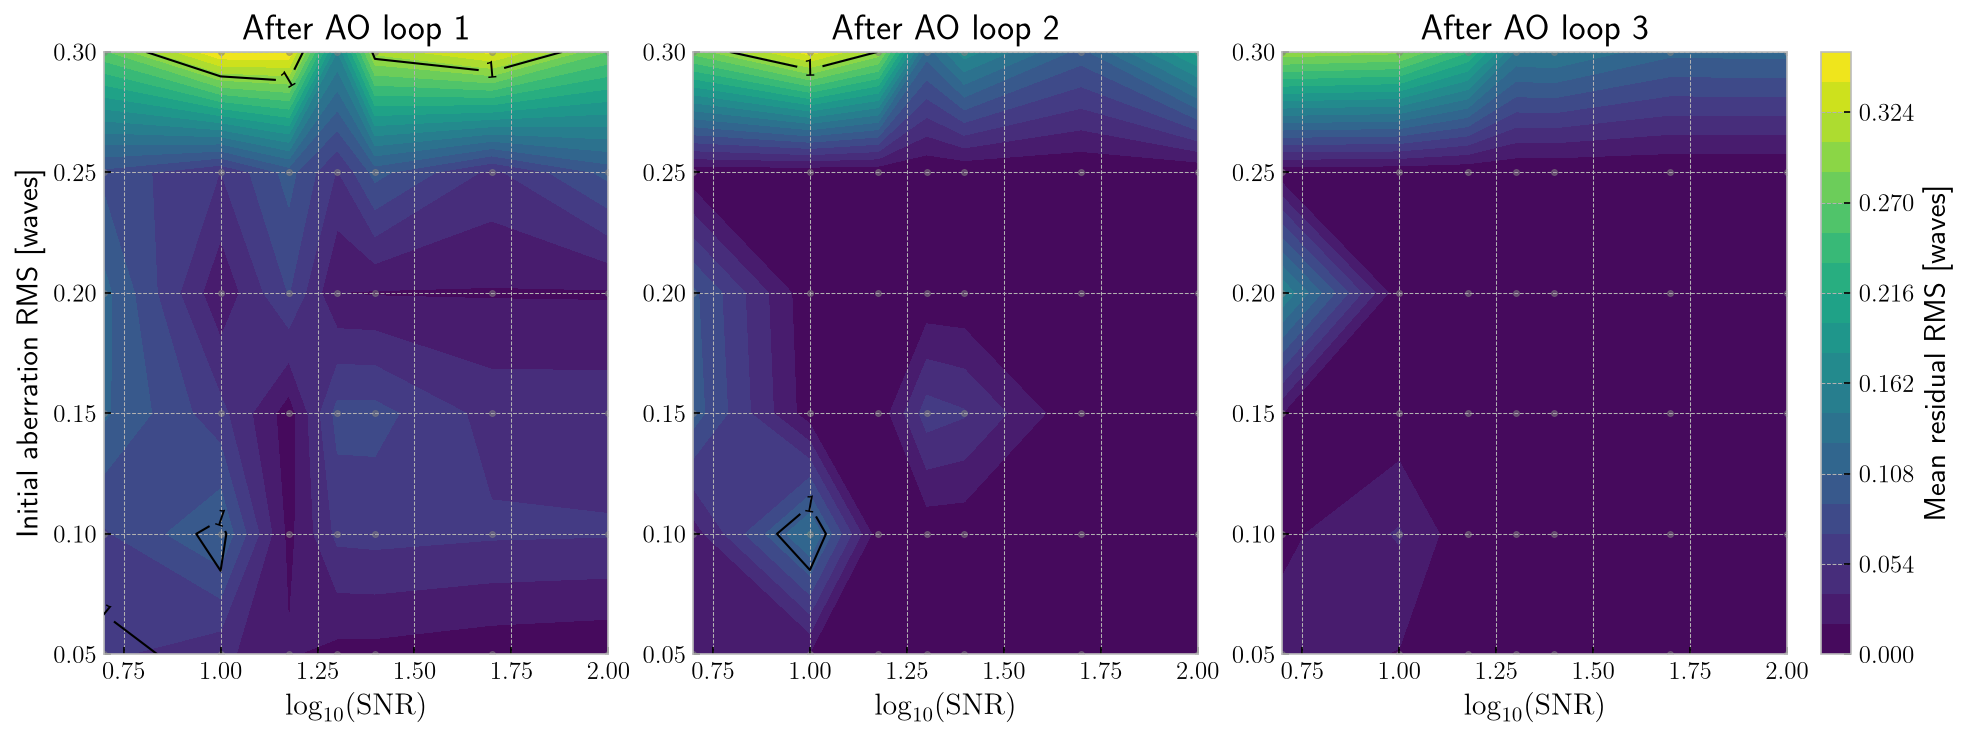

In [105]:
# Filled contours styled like the rho maps in lambda_test.ipynb.
# Black contour: residual RMS equals initial RMS (no net improvement).
fig = plt.figure(figsize=(13, 4.8), dpi=150, layout="constrained")
layout = fig.add_gridspec(1, NUM_AO_LOOPS+1, width_ratios=[1]*NUM_AO_LOOPS+[0.06])
snr_order = np.argsort(SNR_VALUES)
rms_order = np.argsort(INITIAL_RMS_VALUES)
contour_x = np.log10(np.asarray(SNR_VALUES)[snr_order])
contour_y = np.asarray(INITIAL_RMS_VALUES)[rms_order]
sampled_x, sampled_y = np.meshgrid(contour_x, contour_y)
contour_values = mean_residual_rms[rms_order][:, snr_order, :]
color_max = max(float(np.nanmax(contour_values)), np.finfo(float).eps)
levels = np.linspace(0, color_max, 21)
norm = plt.Normalize(0, color_max)
has_contour_grid = len(contour_x) >= 2 and len(contour_y) >= 2
if not has_contour_grid:
    print("Contours need at least two SNR and two RMS values; displaying sampled points.")
for loop in range(NUM_AO_LOOPS):
    ax = fig.add_subplot(layout[0, loop])
    values = contour_values[:, :, loop]
    if has_contour_grid:
        im = ax.contourf(contour_x, contour_y, values,
                         levels=levels, norm=norm, cmap="viridis")
        ratio = values/contour_y[:, None]
        if np.nanmin(ratio) < 1 < np.nanmax(ratio):
            boundary = ax.contour(contour_x, contour_y, ratio,
                                  levels=[1], colors="black", linewidths=1)
            ax.clabel(boundary, fmt="%g")
        ax.scatter(sampled_x.ravel(), sampled_y.ravel(), s=8, c="gray", alpha=0.5)
    else:
        im = ax.scatter(sampled_x.ravel(), sampled_y.ravel(), c=values.ravel(),
                        s=80, norm=norm, cmap="viridis")
        ax.set_xticks(contour_x)
        ax.set_yticks(contour_y)
    ax.set_xlabel(r"$\log_{10}(\mathrm{SNR})$")
    ax.set_ylabel("Initial aberration RMS [waves]" if loop == 0 else "")
    ax.set_title(f"After AO loop {loop+1}")
fig.colorbar(im, cax=fig.add_subplot(layout[0, -1]), label="Mean residual RMS [waves]")
fig.savefig(FIGURES_DIR / "ao_loop_contours_new.png", bbox_inches="tight")
plt.show()


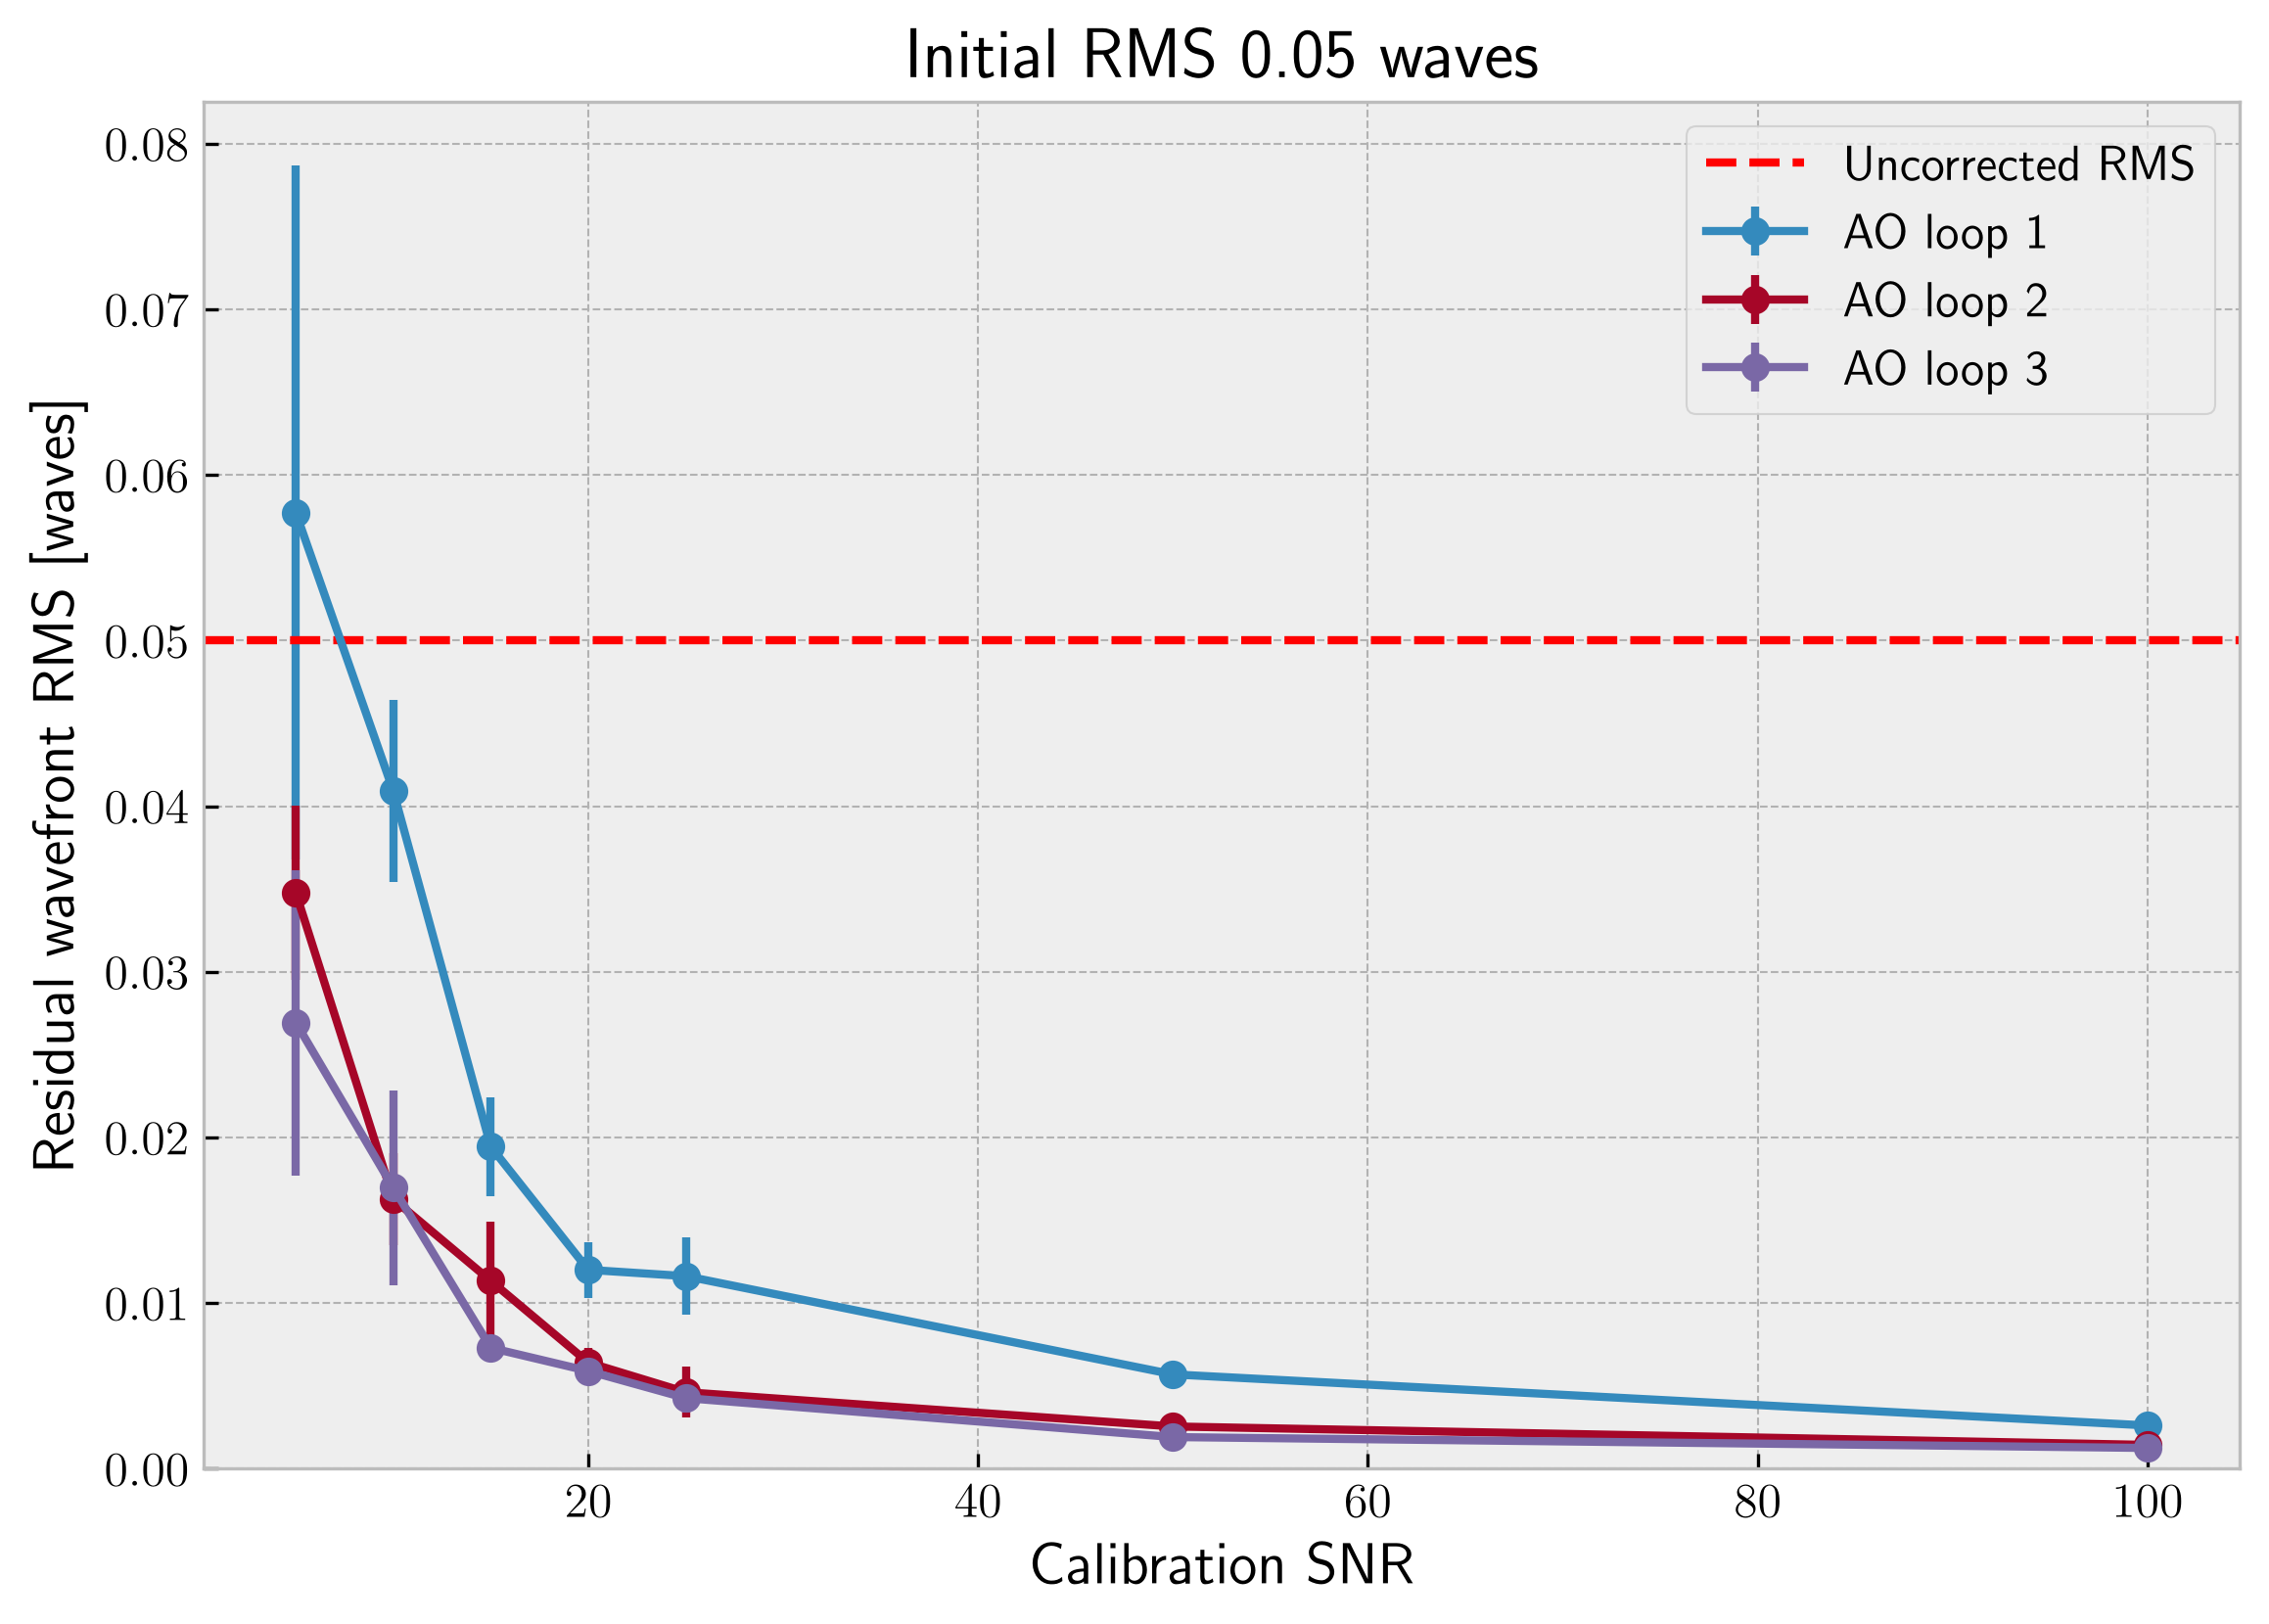

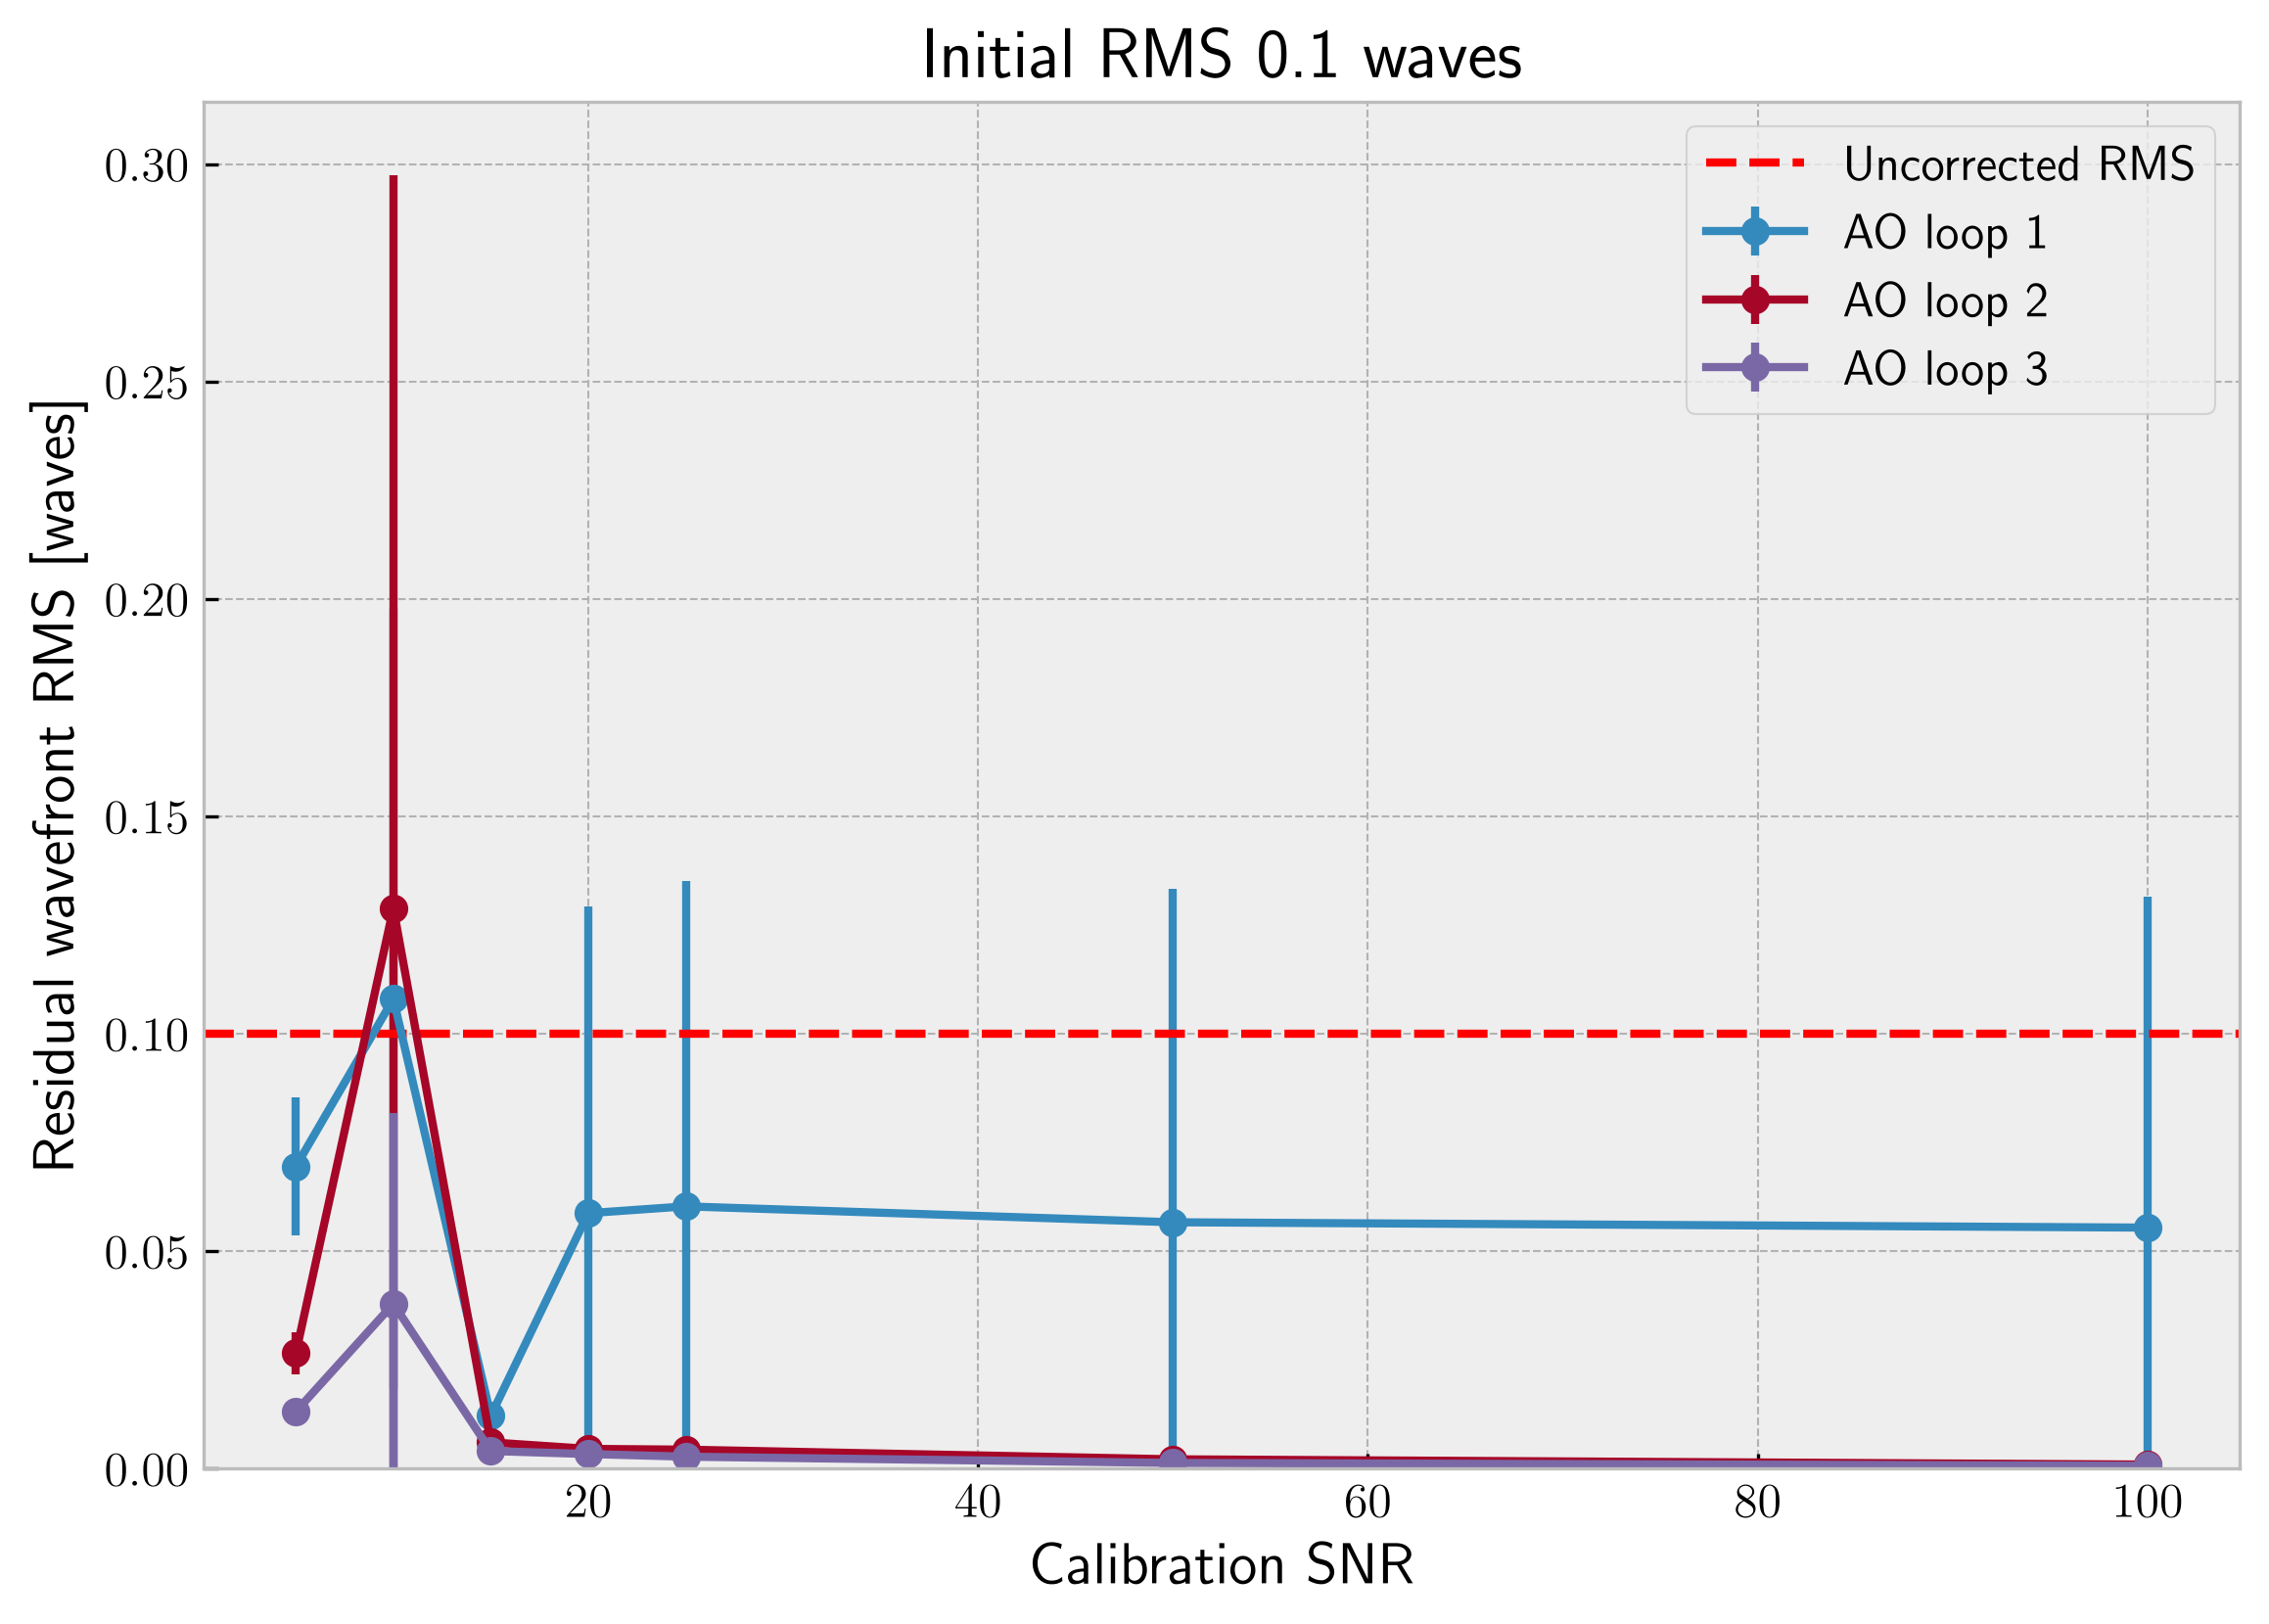

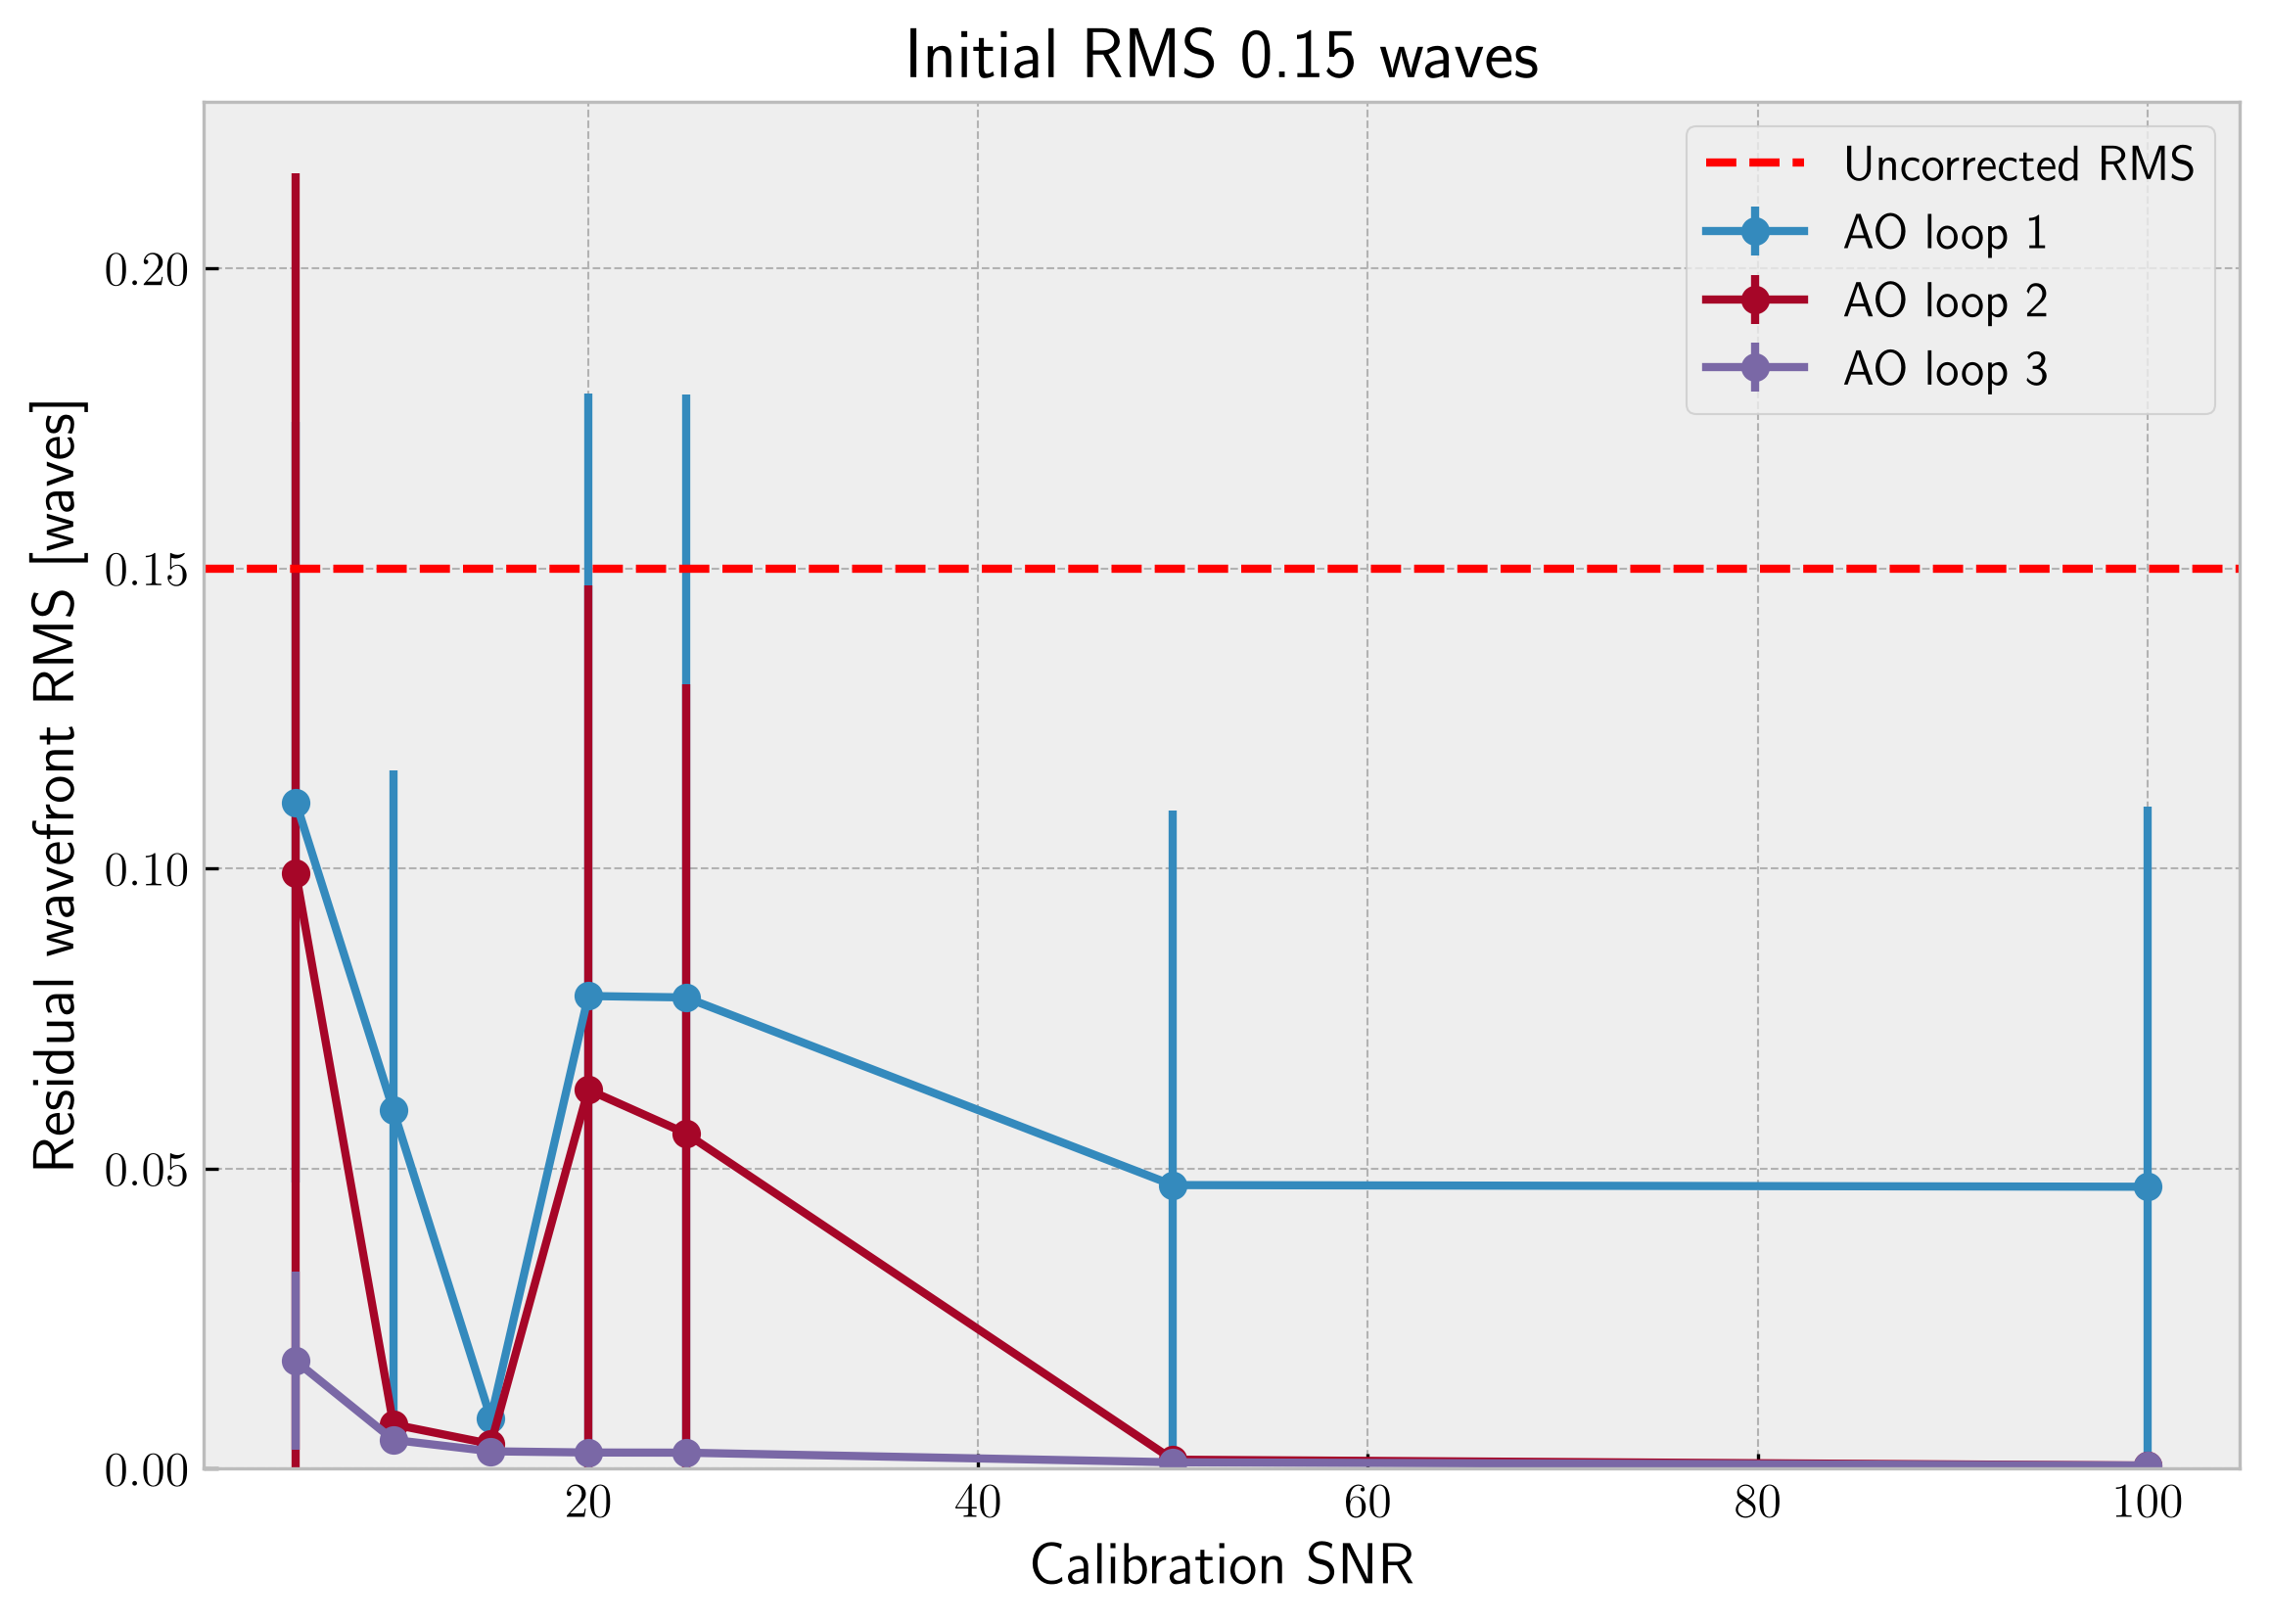

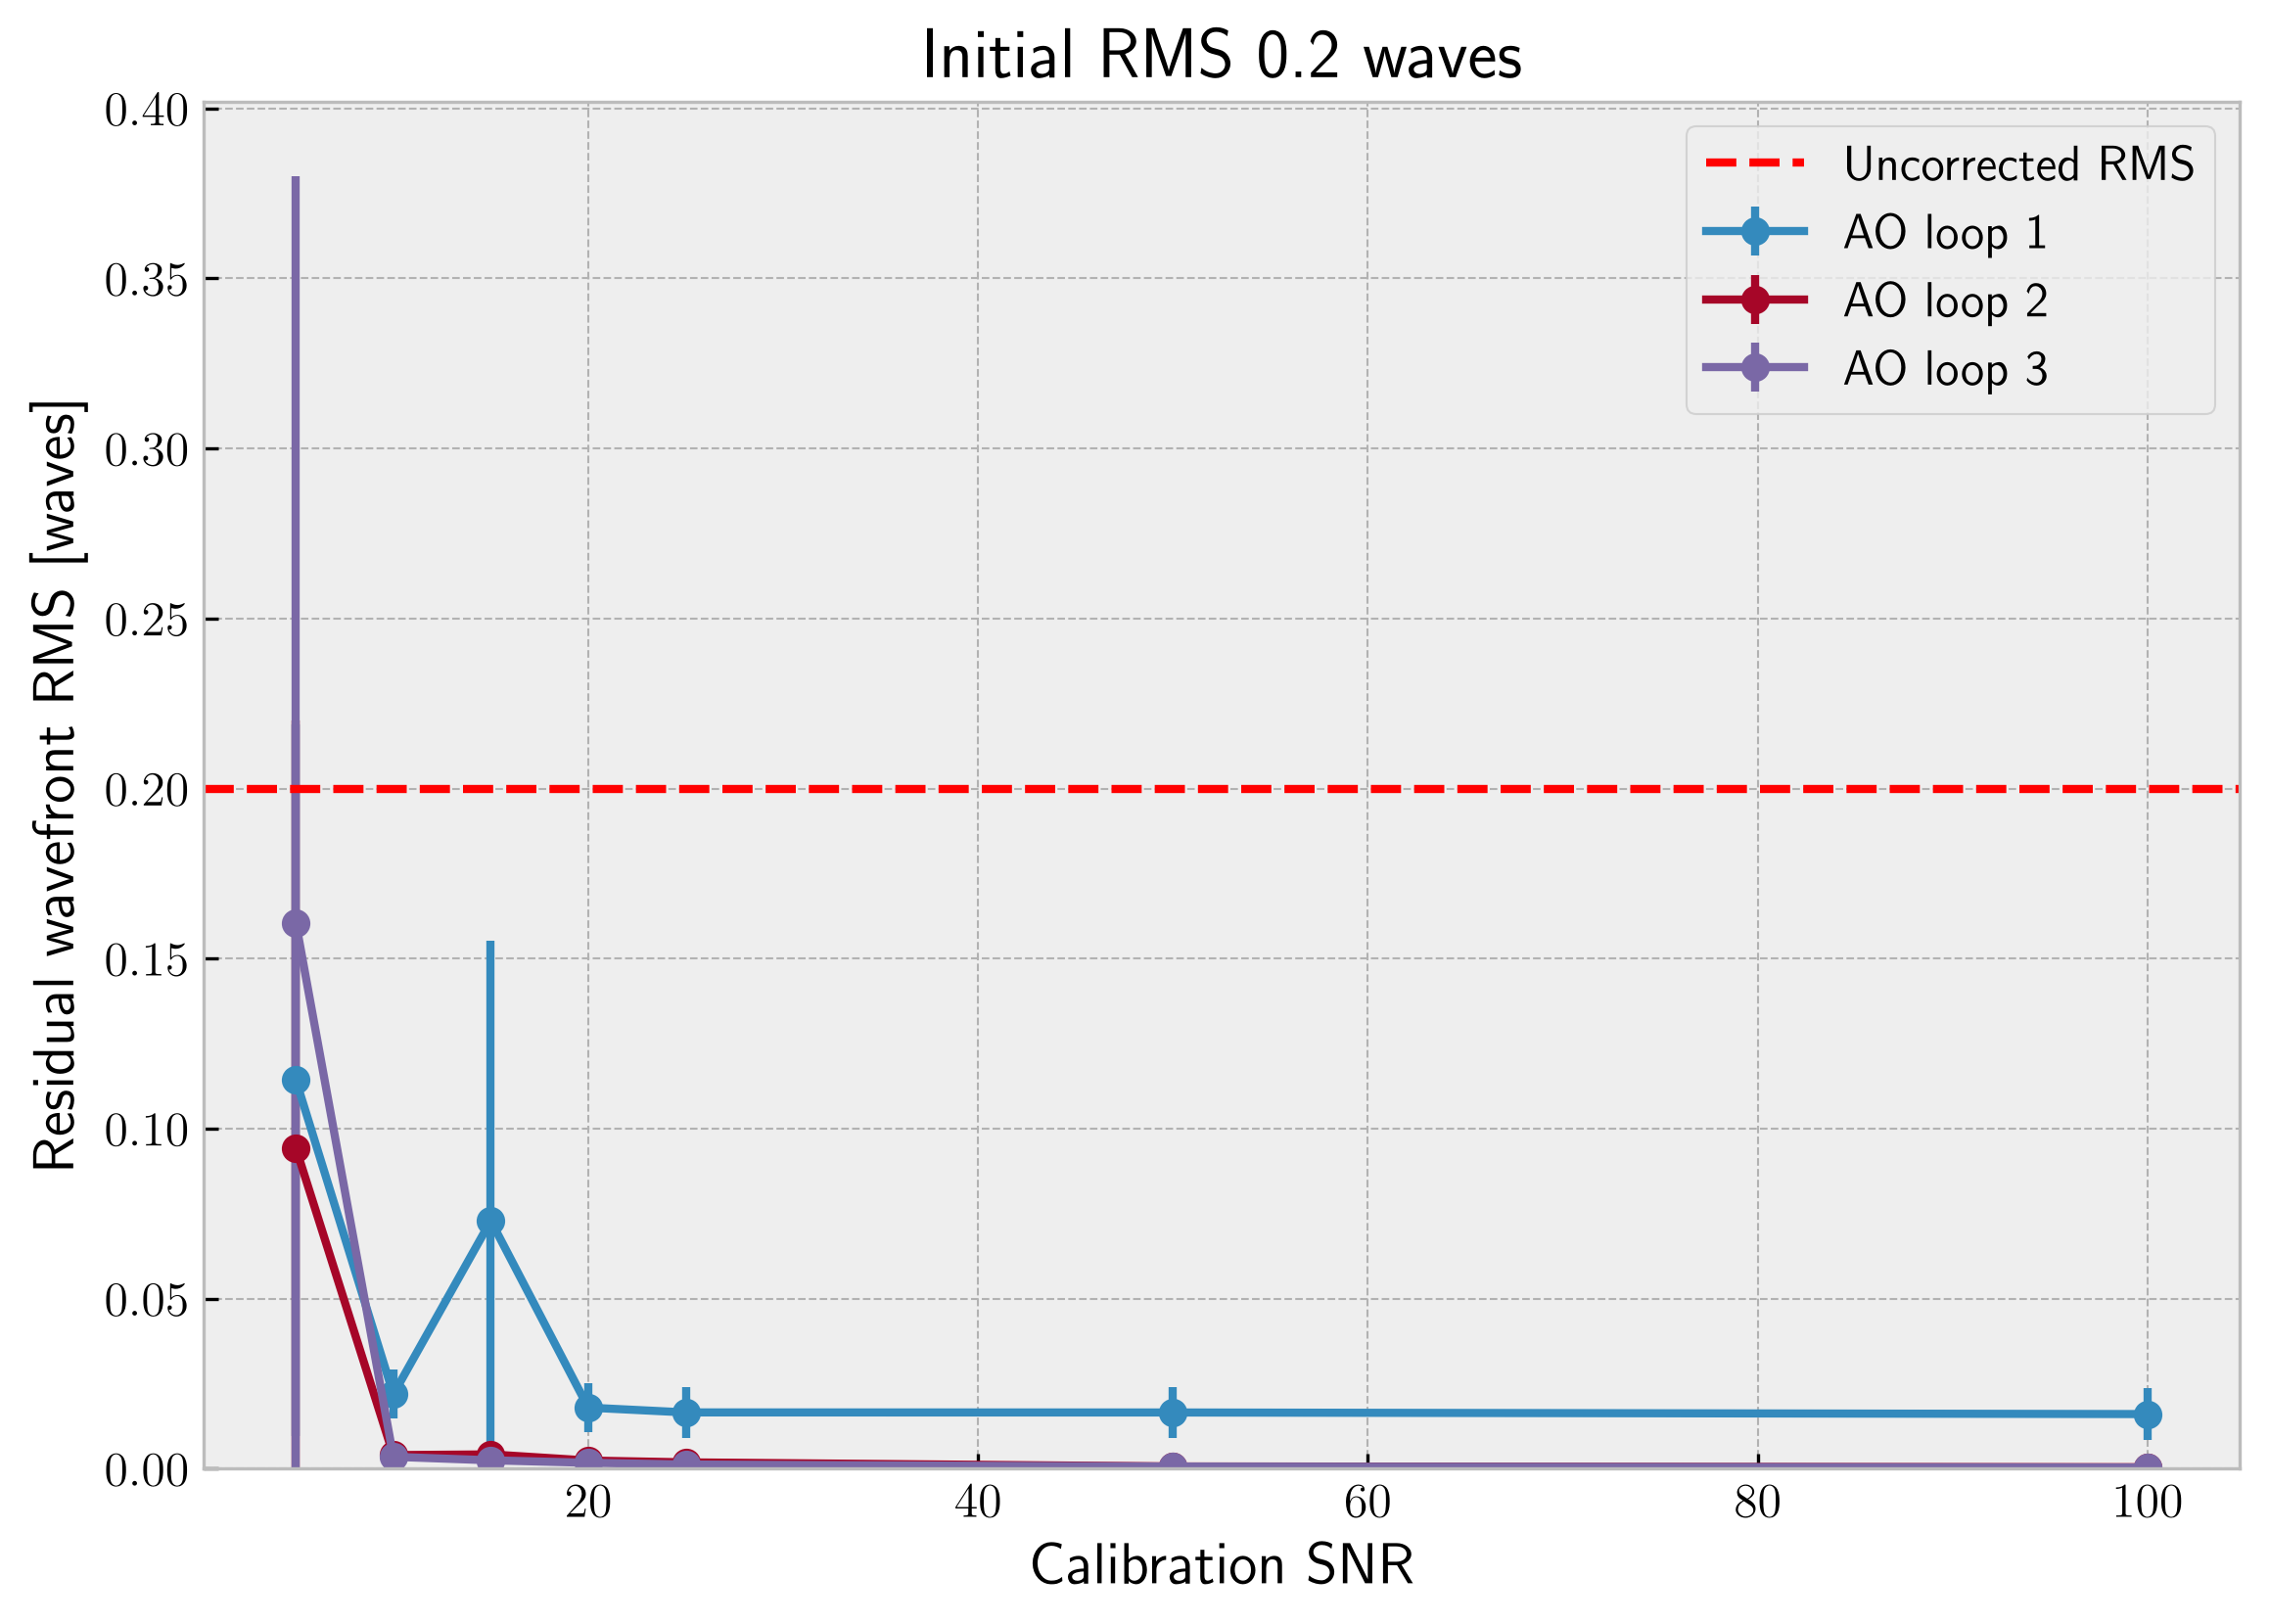

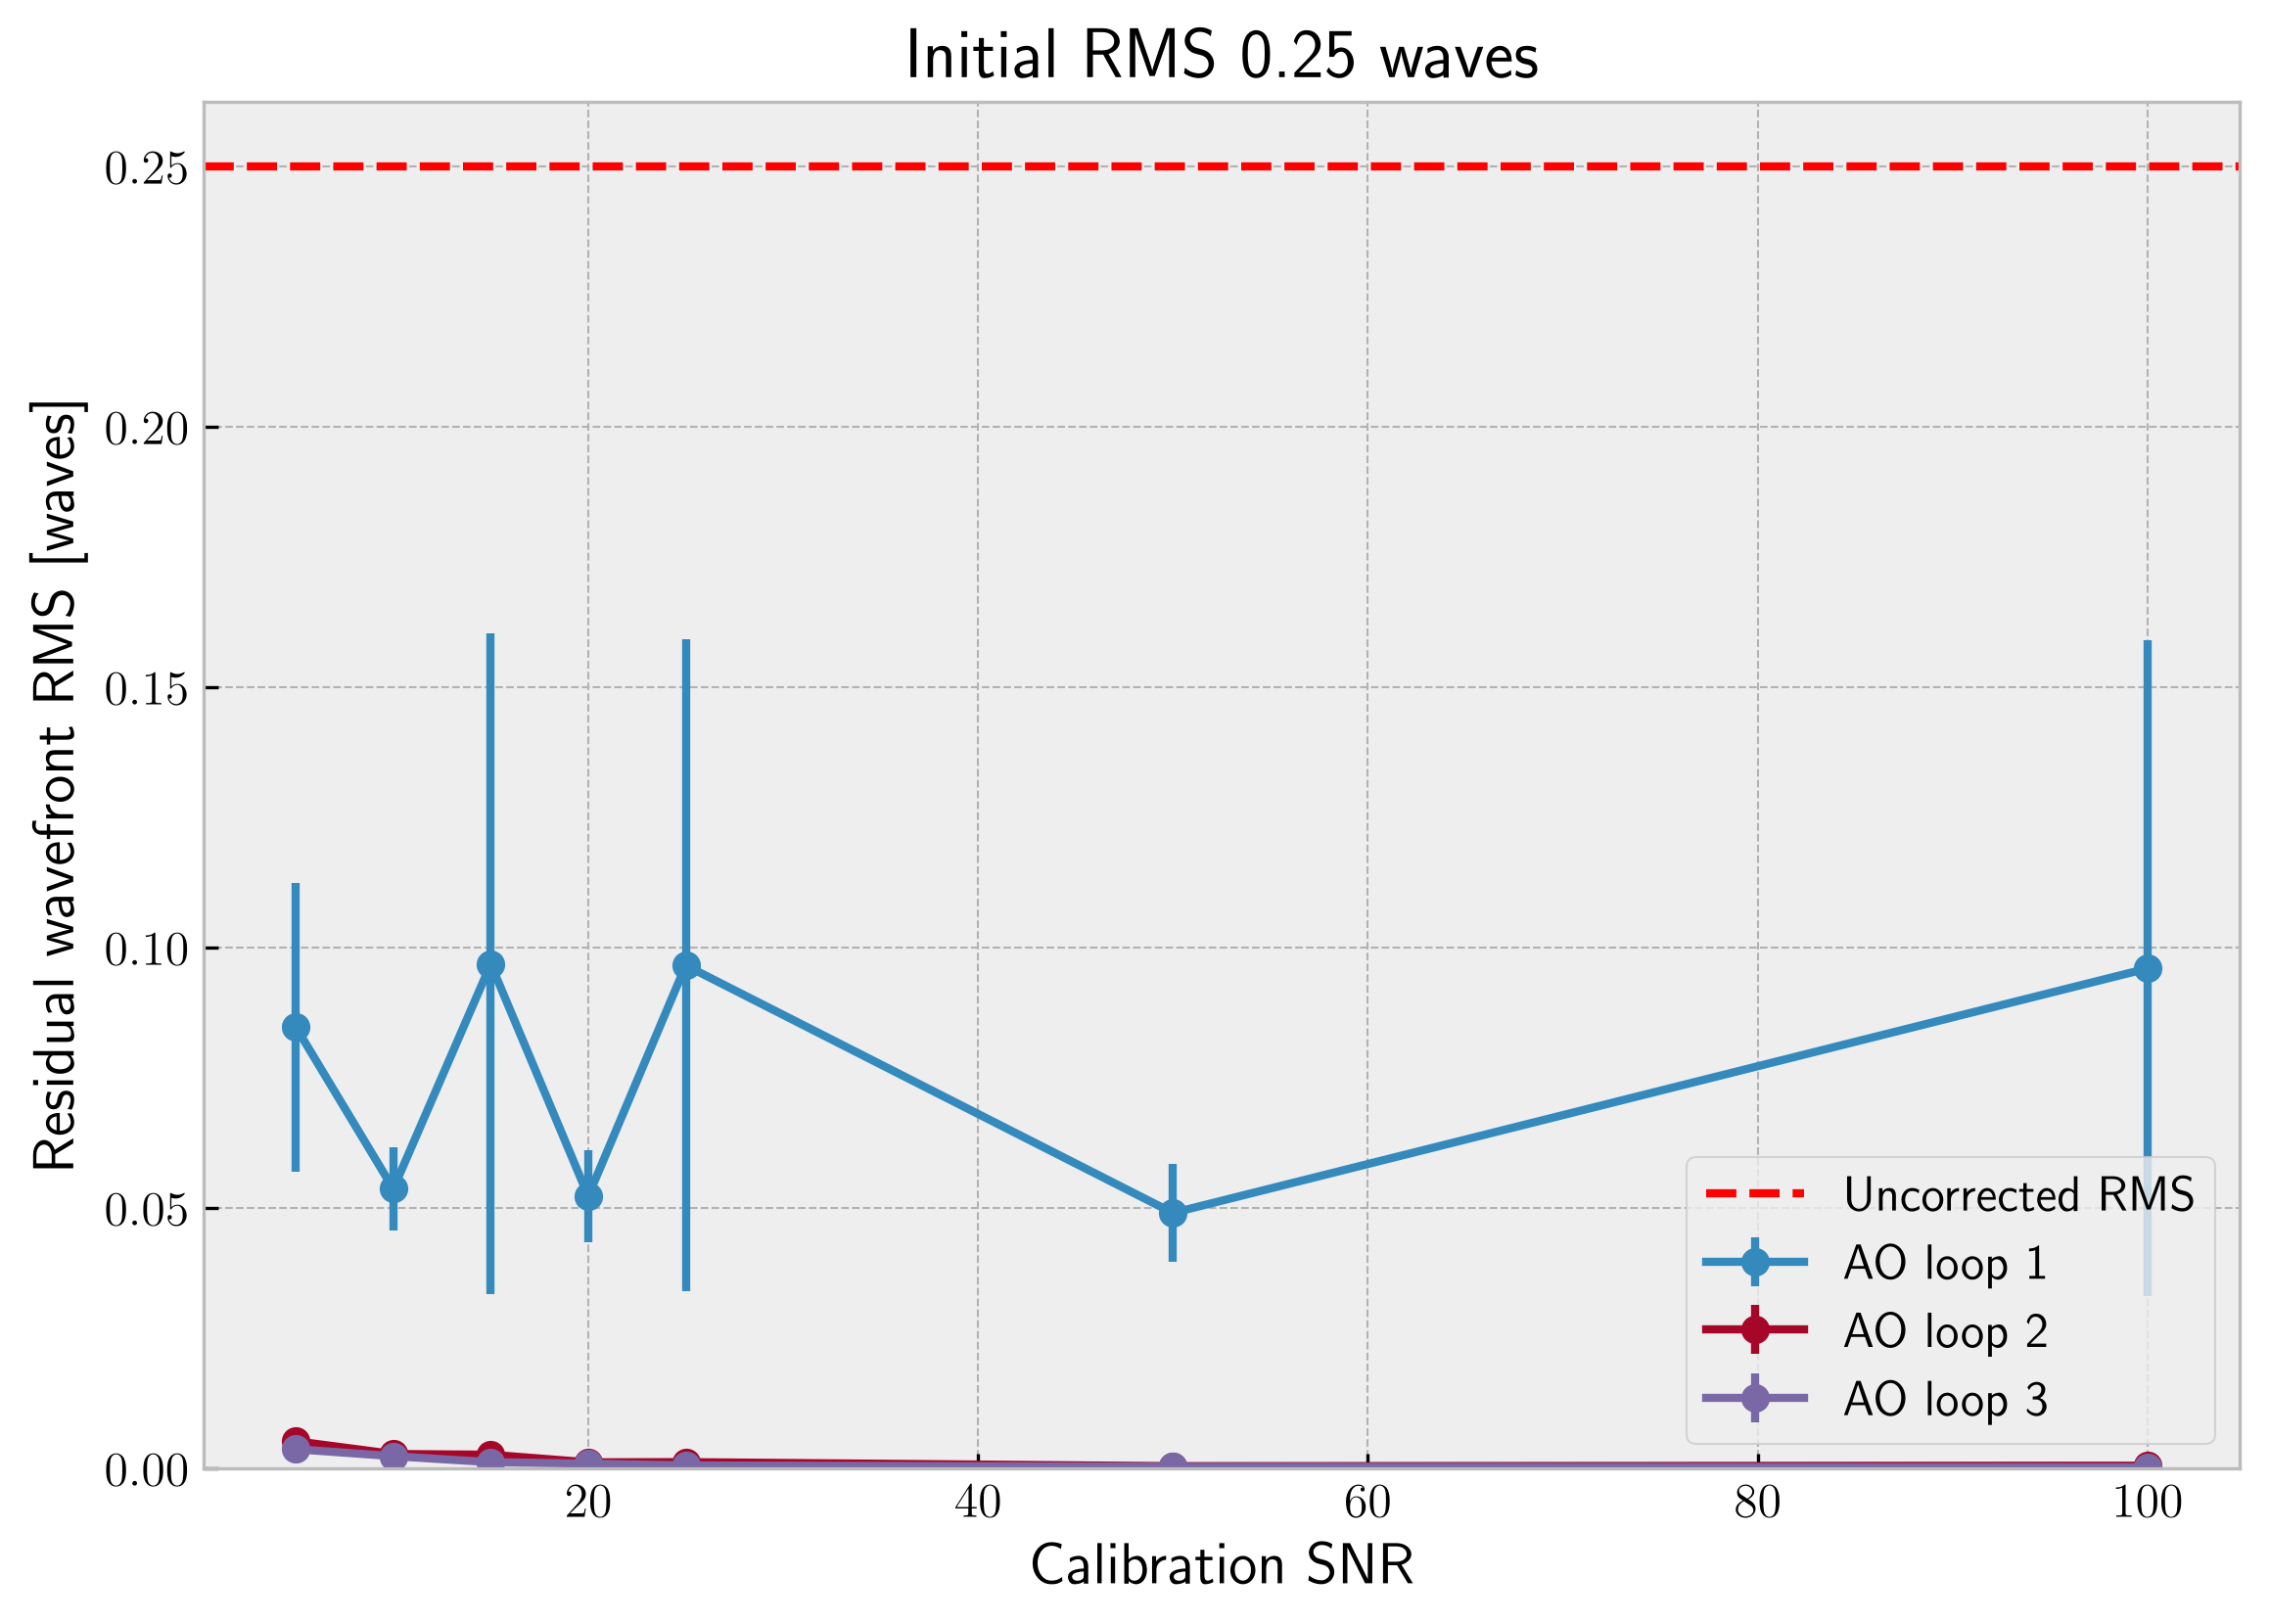

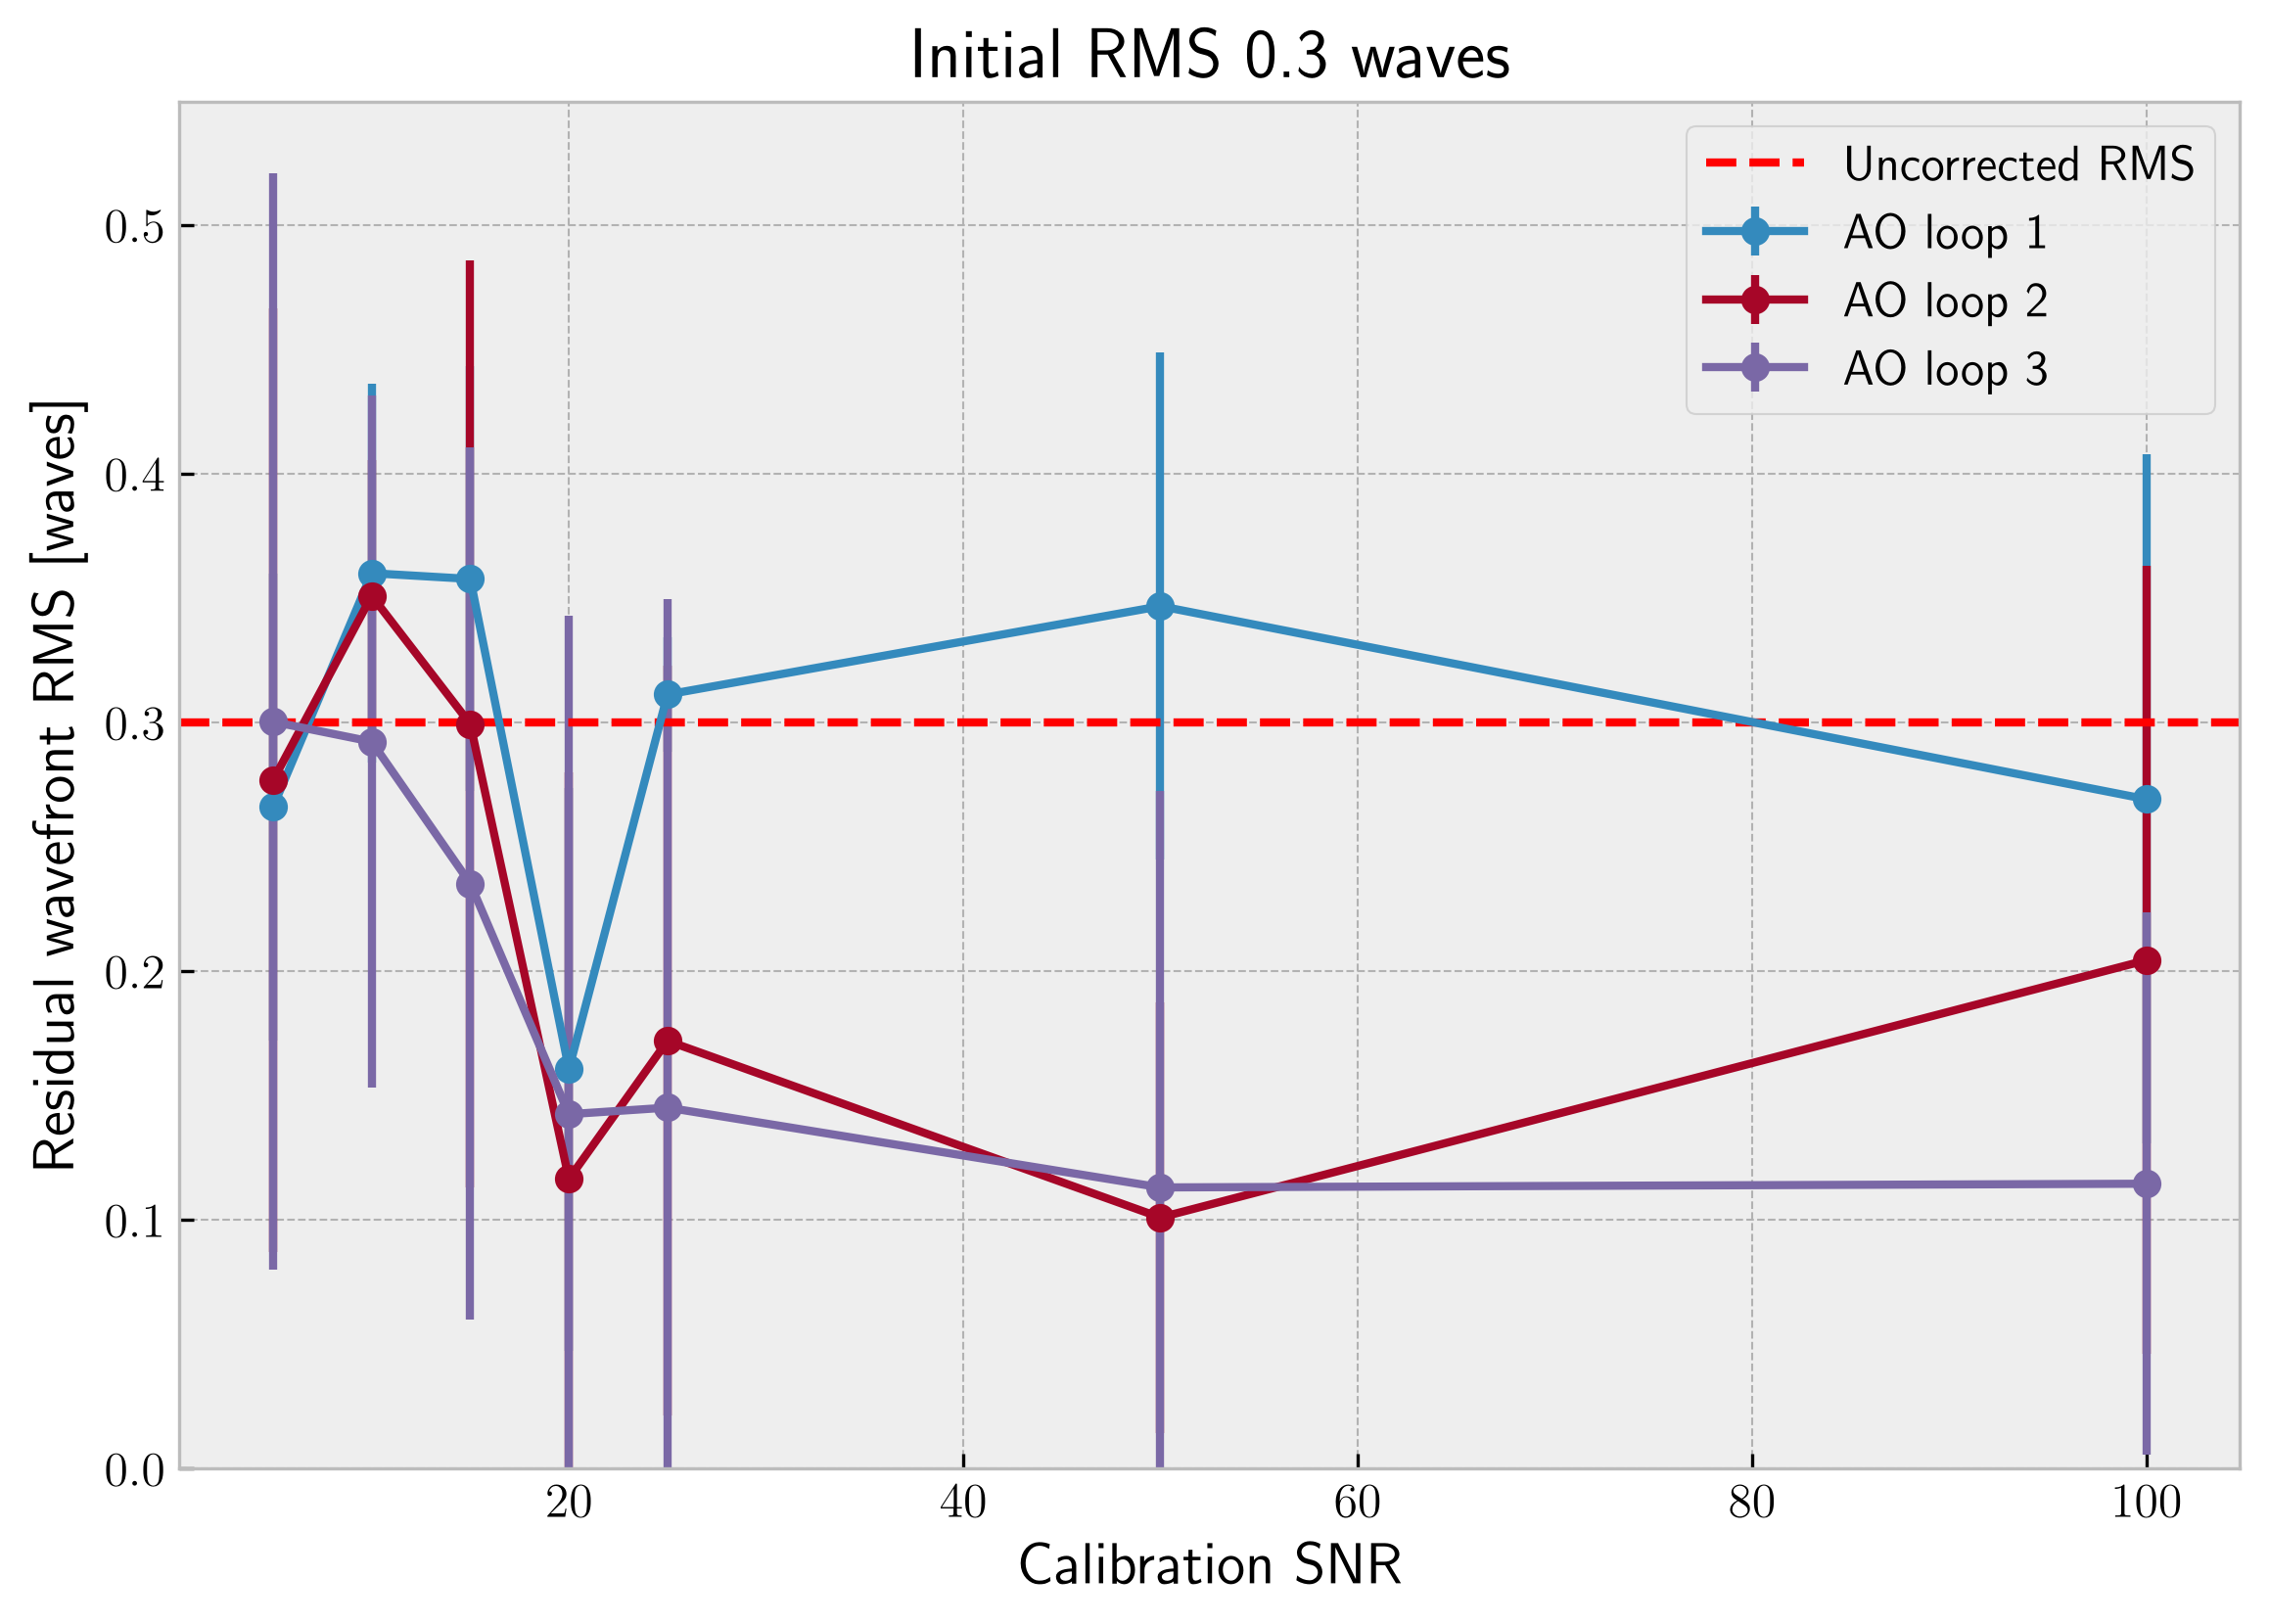

Loop 1: optimizer converged in 123/126 runs; mean residual/initial RMS=0.488
Loop 2: optimizer converged in 113/126 runs; mean residual/initial RMS=0.250
Loop 3: optimizer converged in 89/126 runs; mean residual/initial RMS=0.179


In [100]:
# Relative residual: below 1 means improvement, above 1 means degradation.
relative_residual = mean_residual_rms/INITIAL_RMS_VALUES[:, None, None]
for rms_index, initial_rms in enumerate(INITIAL_RMS_VALUES):
    fig, ax = plt.subplots(layout="constrained")
    #NUM_AO_LOOPS
    for loop in range(3):
        mean = mean_residual_rms[rms_index, :, loop]
        std = std_residual_rms[rms_index, :, loop]
        ax.errorbar(SNR_VALUES, mean, std, marker="o", label=f"AO loop {loop+1}")
        #if NUM_TRIALS > 1:
            #ax.fill_between(SNR_VALUES, np.maximum(0, mean-std), mean+std, alpha=.15)
    ax.axhline(initial_rms, c="red", ls="dashed", label="Uncorrected RMS")
    ax.set_xlabel("Calibration SNR")
    ax.set_ylabel("Residual wavefront RMS [waves]")
    ax.set_title(f"Initial RMS {initial_rms:g} waves")
    ax.set_ylim(bottom=0)
    ax.legend()
    plt.savefig(FIGURES_DIR / f"ao_loop_init_rms_{initial_rms}_new.png")
    plt.show()
for loop in range(NUM_AO_LOOPS):
    print(f"Loop {loop+1}: optimizer converged in {optimizer_success[..., loop].sum()}/"
          f"{optimizer_success[..., loop].size} runs; "
          f"mean residual/initial RMS={relative_residual[..., loop].mean():.3f}")

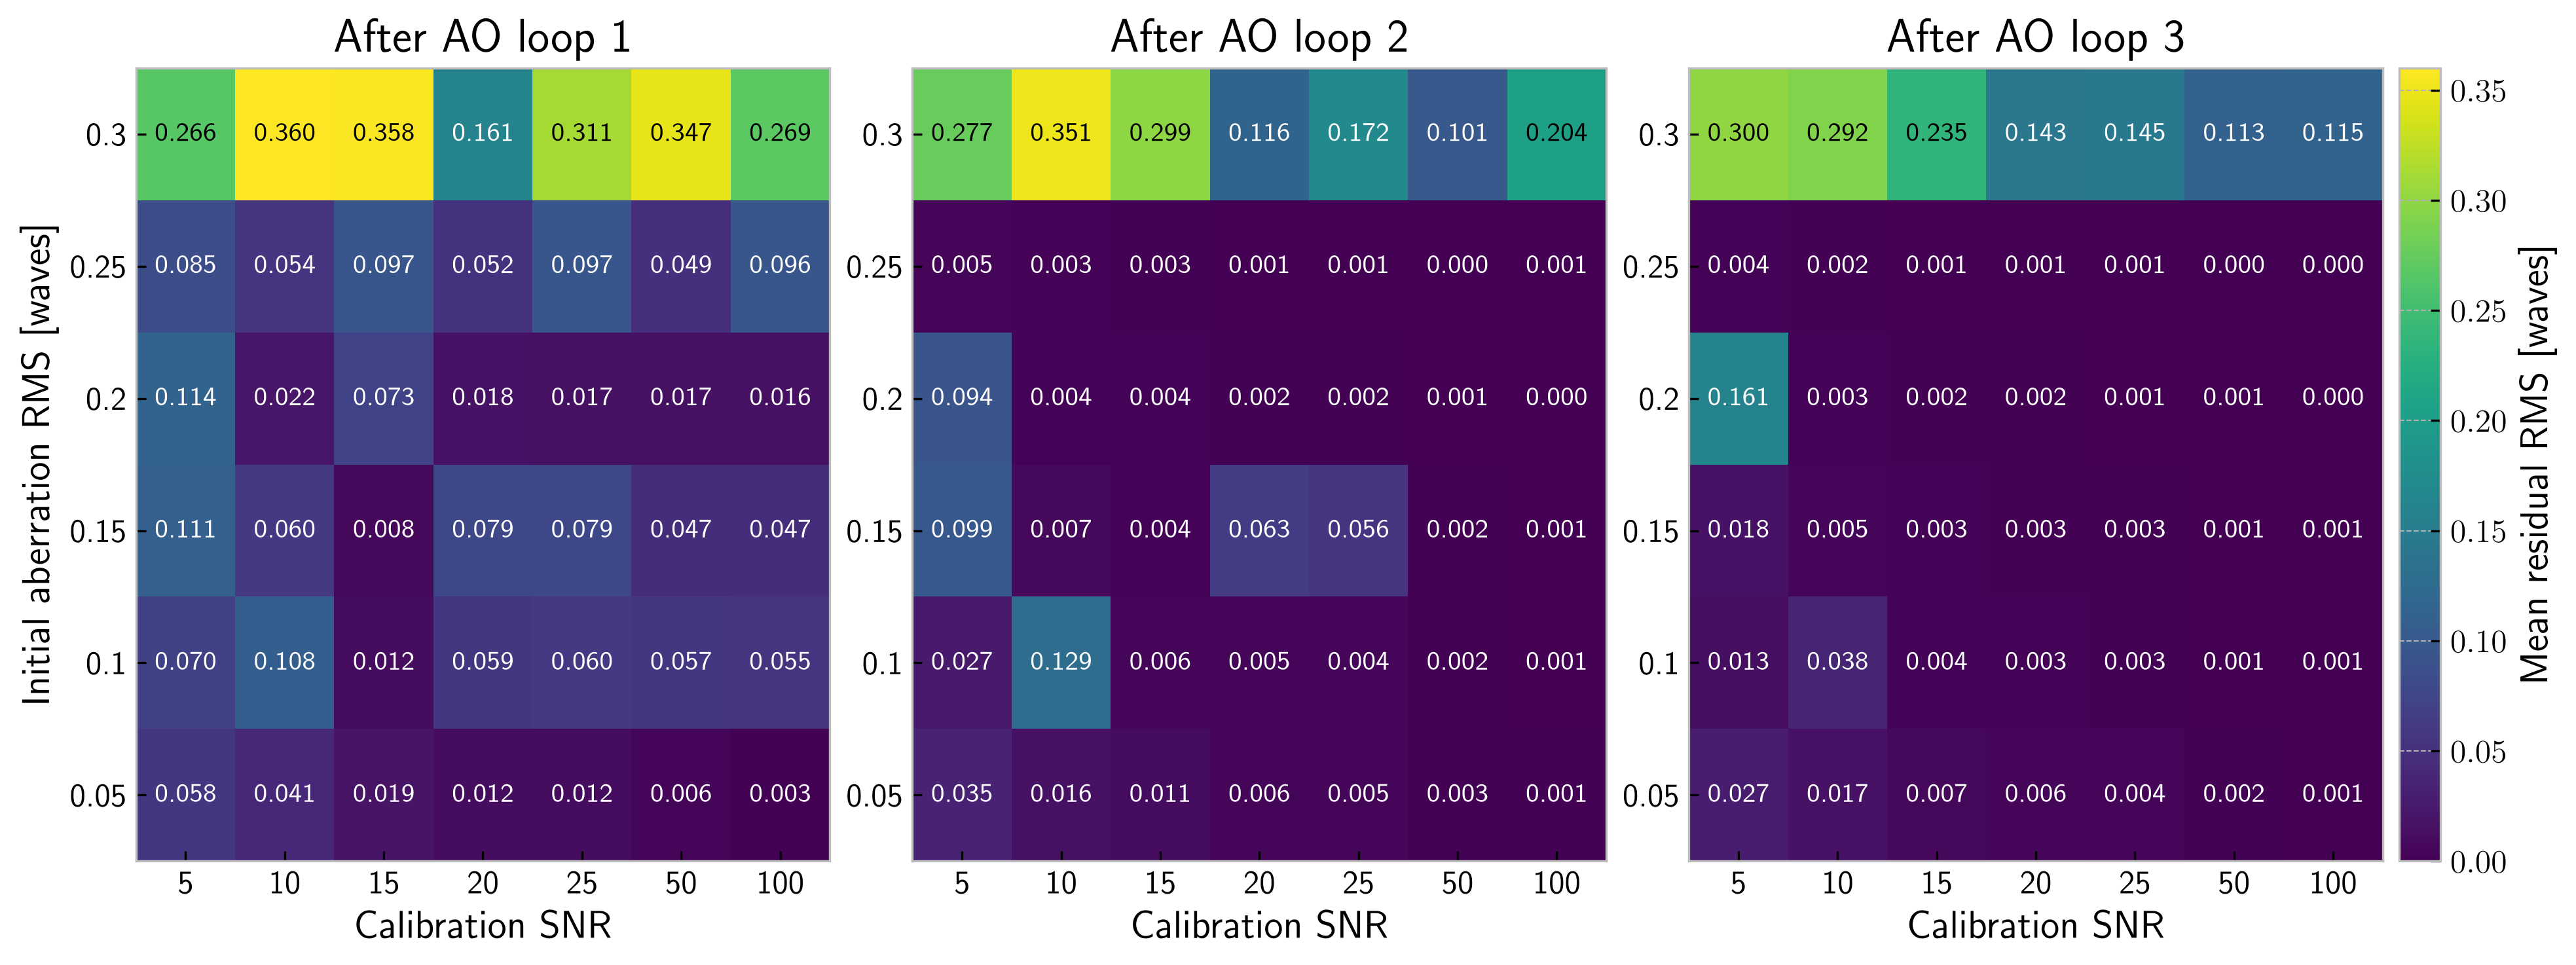

In [104]:
#Common color scale for direct comparison after loops 1, 2, and 3.
fig = plt.figure(figsize=(13, 4.8), layout="constrained")
layout = fig.add_gridspec(1, NUM_AO_LOOPS+1, width_ratios=[1]*NUM_AO_LOOPS+[0.06])
norm = plt.Normalize(0, max(float(mean_residual_rms.max()), np.finfo(float).tiny))
for loop in range(NUM_AO_LOOPS):
    ax = fig.add_subplot(layout[0, loop])
    im = ax.imshow(mean_residual_rms[:, :, loop], origin="lower", aspect="auto", norm=norm, cmap="viridis")
    ax.set_xticks(np.arange(len(SNR_VALUES)), [f"{v:g}" for v in SNR_VALUES])
    ax.set_yticks(np.arange(len(INITIAL_RMS_VALUES)), [f"{v:g}" for v in INITIAL_RMS_VALUES])
    ax.set_xlabel("Calibration SNR")
    ax.set_ylabel("Initial aberration RMS [waves]" if loop == 0 else "")
    ax.set_title(f"After AO loop {loop+1}")
    ax.grid(False)
    for ri in range(len(INITIAL_RMS_VALUES)):
        for si in range(len(SNR_VALUES)):
            value = mean_residual_rms[ri, si, loop]
            ax.text(si, ri, f"{value:.3f}", ha="center", va="center",
                    color="white" if norm(value) < .55 else "black", fontsize=10)
fig.colorbar(im, cax=fig.add_subplot(layout[0, -1]), label="Mean residual RMS [waves]")
plt.savefig(FIGURES_DIR / "ao_loop_confusion.png")
plt.show()

## Correction examples from saved results
Four states at z=0 with no phase diversity: before correction and after each of the three loops. Corner insets show truth plus the cumulative signed SLM command. Images receive fresh Poisson noise using the saved fixed exposure; they are illustrative, not the original acquisitions. Run the import/setup cell first; no sweep execution is needed.

In [ ]:
# Replay saved correction states without rerunning the sweep or optimizer.
import importlib
from systematic_testing.correction_examples import plot_pd_correction_examples as correction_examples
importlib.reload(correction_examples)  # Refresh styles and fixed phase limits in an existing kernel.
from systematic_testing.correction_examples.plot_pd_correction_examples import (
    DEFAULT_DATA, DEFAULT_CASES, plot_correction_example,
)
EXAMPLE_RESULTS_PATH = DEFAULT_DATA
EXAMPLE_CASES = DEFAULT_CASES  # (initial RMS, calibration SNR, zero-based trial)
EXAMPLE_OUTPUT = ROOT / "systematic_testing" / "correction_examples" / "figures" / "pd_correction_examples_noisy"
EXAMPLE_OUTPUT.mkdir(parents=True, exist_ok=True)
with np.load(EXAMPLE_RESULTS_PATH, allow_pickle=False) as example_data:
    for rms, snr, trial in EXAMPLE_CASES:
        fig, axes = plot_correction_example(example_data, rms, snr, trial, noisy=True)
        stem = f"rms{rms:g}_snr{snr:g}_trial{trial+1}"
        for extension in ("png", "pdf"):
            fig.savefig(EXAMPLE_OUTPUT / f"{stem}.{extension}", dpi=200, bbox_inches="tight")
        plt.show()


Inset phase limits are fixed at $-2\pi$ and $2\pi$ radians. Rerun the setup/import cell to reload the plotting helper in an existing kernel.
